# E13-H71 - partial-matching statement map

**Author**: Konrad Jelen (kj) <br>
**Date**: 2026-10-09 <br>
**Record**: `### E13-H71 partial-matching-map` in `docs/experiments/wmd-docdistance-experiments.md` <br>
**Campaign stage**: E13 stage A (measure) - no source edit, every variant lives in this notebook <br>
**Execution model**: opus <br>

Measures whether a one-to-one statement matching with a calibrated cost cutoff labels kept, removed and
added statements on edited document pairs, where the shipped per-statement flags (`no_counterpart`, target
`min_incoming_cost`) are expected to stay silent. Both distances (`smd`, `order_gap`) are held fixed: the
lever is the per-statement map only.

The shipped map reads the balanced transport plan, which must place each statement's mass 1/n into targets
of capacity 1/m. The lever replaces that reading with a unit-capacity assignment on the capped ground cost:

$$\pi^{*} = \arg\min_{\pi} \sum_{(i,j) \in \pi} \min(C_{ij},\, c)$$

A pair (i, j) ∈ π* with Cᵢⱼ < c is **kept** on both sides. Every other A statement is **removed** and every
other B statement is **added**. The score is the macro-F1 over the three classes, pooled over the A-side and
B-side statements of every edited pair:

$$\text{macro-F1} = \tfrac{1}{3}\left(F1_{\text{kept}} + F1_{\text{removed}} + F1_{\text{added}}\right)$$

## Approach
1. **Sanity check** - verify that every back-translation list aligns one-to-one with its base document; a base that does not align is excluded
2. **Kill-gate** - on each calibration split, costs of true paraphrase pairs against the cost of the nearest non-counterpart statement; no cutoff at balanced accuracy ≥ 0.90 ends the run
3. **Labelled edits** - k ∈ {1, 2, 3} deletions, insertions and replacements per base document, with and without paraphrase of the kept statements; labels read from the construction
4. **Shipped baseline** - `DocDistance.semantic_distance_with_details` on every edited pair; the same call supplies the embeddings behind the cost matrix
5. **Calibration and scoring** - choose c on 5 base documents, score on the other 5, then swap
6. **Guardrails** - `V` on the ibm panel, `smd` and `order_gap` equality before and after, source tree fingerprint

## Outputs
- `reports/E13-H71-partial-matching-map-metrics.json` - every measured number, the two cost populations with percentiles, bar and guardrail readings
- In-notebook: gate populations, calibration curves, held-out F1 per class, per-condition error rates

## Environment

CPU only: the campaign runs on CPU and the shipped default encoder is OpenVINO INT8. CUDA is masked before
torch is imported, so the SaT segmenter resolves to CPU as well and no GPU is selected.

In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""  # CPU pin, set before torch is imported
# the kernel starts in notebooks/experiments/, so the readiness gate is pointed at the repository's docdistance.json
os.environ["DOCDISTANCE_HOME"] = "/home/lab/workspace/learning/projects/docdistance"
os.environ["CI"] = "true"  # switches the OpenVINO usage telemetry off (DEF-DEPS-11)
os.environ["HF_HUB_OFFLINE"] = "1"  # no network access: every model resolves from the local mirrors
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import sys
import warnings

warnings.filterwarnings("ignore")

import torch

print(f"python {sys.version.split()[0]} at {sys.executable}\n"
      f"torch {torch.__version__} | cuda visible: {torch.cuda.is_available()} | device: CPU")

python 3.14.8 at /home/lab/workspace/learning/projects/docdistance/.venv/bin/python
torch 2.11.0+cu130 | cuda visible: False | device: CPU


## Imports

One cell for every import. The shipped library is imported read-only: the notebook wraps or re-reads its
functions and never writes under `src/`.

In [2]:
%load_ext autoreload
%autoreload 2

# Standard library
import hashlib  # source-tree fingerprint and checkpoint key
import json  # fixture, checkpoint and metrics files
import random  # seed
import re  # word tokens for the lexical alignment check
import subprocess  # git status reading for the src-untouched guardrail
import zlib  # stable per-edit seed
from datetime import datetime, timezone  # timestamp in the metrics file
from pathlib import Path  # file paths

# Numerical
import numpy as np  # arrays and percentiles
from scipy.optimize import linear_sum_assignment  # the one-to-one matching solver

# Plotting
import matplotlib.pyplot as plt  # inline figures

# Console output
from rich.console import Console  # one rendered block per result
from rich.panel import Panel  # verdict and configuration blocks
from rich.table import Table  # tabular readings
from tqdm import tqdm  # progress of the long loops, written to the run log

# Shipped library (read only)
import docdistance.pipeline as pipe  # shipped constants and version stamp
from docdistance.distance import cost_matrix  # the shipped ground cost sqrt(2 - 2cos)
from docdistance.pipeline import DocDistance  # the shipped pipeline entry point

console = Console(width=150)
LOG = sys.__stderr__ or sys.stderr  # the kernel's own stderr: nbconvert passes it to the run log


def progress(iterable, description):
    # progress bar written to the run log, so a detached execution can be followed
    return tqdm(iterable, desc=description, file=LOG, mininterval=10.0)


print(f"imports ready | docdistance {pipe._VERSION} | numpy {np.__version__}")

imports ready | docdistance 1.1.5 | numpy 2.4.6


## Reproducibility

One seed. Every edit draws from its own generator keyed by the edit's name, so the fixture does not depend
on loop order and both paraphrase arms of an edit share the same positions and donor statements.

In [3]:
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
print(f"SEED = {SEED} | per-edit generator: np.random.default_rng([SEED, crc32('<base>|<kind>|<k>|<rep>')])")

SEED = 0 | per-edit generator: np.random.default_rng([SEED, crc32('<base>|<kind>|<k>|<rep>')])


## Configuration

Paths, the registered bars, the split, the edit grid and the cutoff grid. The split, the donor rule and the
calibration rule are fixed here, before any measurement:

- **Split** - alternate through the fixture's own base-document order: half A takes positions 0, 2, 4, 6, 8, half B the rest
- **Donors** - an inserted statement comes from another base document of the same half, so no text of the scored half enters a calibration pair
- **Calibration rule** - c is the midpoint of the longest run of grid points at the maximum calibration macro-F1
- **Bar reading** - both directions must meet both conditions of the bar

In [4]:
# Paths
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
FIXTURE_DIR = ROOT / "data/processed/structure-fixture"  # 10 base documents, pre-segmented
PARAPHRASE_DIR = ROOT / "data/interim/structure-paraphrase"  # back-translations, one list per base
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"  # ibm panel of the V guardrail
REPORT = ROOT / "reports/E13-H71-partial-matching-map-metrics.json"  # metrics file written by this notebook
CHECKPOINT_DIR = ROOT / "data/interim/E13-H71"  # per-pair shipped readings (git-ignored)

# Shipped constant read from the source, and the E12-H60 reading the record quotes
SHIPPED_CUT = pipe.NO_COUNTERPART_COST  # 0.6 - the cut behind `no_counterpart` and the added-target reading
E12_H60_MATCHED_MAX = 0.348  # matched-paraphrase maximum as written in the record

# Registered bars, applied literally
GATE_BA_MIN = 0.90  # kill-gate: best balanced accuracy on each calibration split
BAR_MACRO_F1 = 0.90  # held-out macro-F1 over {kept, removed, added}
BAR_DELTA = 0.30  # held-out macro-F1 gain over the shipped-flag baseline
PRED_CLASS_F1 = 0.90  # prediction: removed and added F1 of the partial matching
PRED_SHIPPED_F1 = 0.30  # prediction: removed and added F1 of the shipped flags stay at or below this
NULL_DELTA = 0.02  # a gain below this in both directions reads as indistinguishable from the baseline

# Split (calibration half, scored half), fixed before any measurement
HALF = {"A": ("gold", "v1", "opus", "haiku", "werg-b"), "B": ("gold-2", "v2", "sonnet", "werg-a", "werg-c")}
DIRECTIONS = (("A", "B"), ("B", "A"))

# Edit grid
EDIT_KINDS = ("deletion", "insertion", "replacement")
EDIT_KS = (1, 2, 3)  # edited statements per pair
PARAPHRASE_ARMS = (False, True)  # kept statements identical to A, or back-translated
REPS = 5  # random draws per (base, kind, k); both paraphrase arms share one draw

# Cutoff grid and checkpoint cadence
C_GRID = np.round(np.arange(0.05, 1.0 + 1e-9, 0.005), 3)  # candidate cutoffs on the [0, sqrt(2)] ground-cost scale
FIXED_CUTOFFS = (0.28, 0.30, 0.31, 0.325, 0.35, 0.40, 0.44, 0.50, 0.60)  # grid points read off both curves, no tuning
CHECKPOINT_EVERY = 100  # pairs between two checkpoint writes

# Classes
KEPT, REMOVED, ADDED = 0, 1, 2
CLASS_NAMES = ("kept", "removed", "added")

# ibm panel of the standing V guardrail: (file, label, tier)
PANEL = (
    ("exec-summary-gold-opus-4-6.md", "gold", "anchor"),
    ("exec-summary-gold-2-opus-4-6.md", "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md", "v1", "gold"),
    ("exec-summary-2-opus-4-6.md", "v2", "gold"),
    ("exec-summary-opus-4-6.md", "opus", "gold"),
    ("exec-summary-sonnet-4-6.md", "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md", "haiku", "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adversarial"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adversarial"),
    ("exec-summary-adv2-a-haiku-4-5.md", "adv2-a", "adversarial"),
    ("exec-summary-adv2-b-haiku-4-5.md", "adv2-b", "adversarial"),
)

# One palette for rich output and every figure
COLOR = {
    "proposed": "#3498DB",  # partial matching
    "shipped": "#E74C3C",  # shipped flags
    "pair": "#2ECC71",  # true paraphrase pairs
    "neighbour": "#F39C12",  # nearest non-counterpart statements, removed statements
    "added": "#34495E",  # added statements
    "cutoff": "#9B59B6",  # calibrated cutoffs
    "reference": "#7F8C8D",  # bars and shipped constants
}

console.print(f'''[bold cyan]Configuration[/bold cyan]
[dim]{"─" * 60}[/dim]
[bold]Fixture[/bold]
  Base documents: [cyan]{FIXTURE_DIR.relative_to(ROOT)}[/cyan]
  Paraphrases: [cyan]{PARAPHRASE_DIR.relative_to(ROOT)}[/cyan]
  Half A: [cyan]{", ".join(HALF["A"])}[/cyan]
  Half B: [cyan]{", ".join(HALF["B"])}[/cyan]

[bold]Edit grid[/bold]
  Kinds: [yellow]{", ".join(EDIT_KINDS)}[/yellow]
  k: [yellow]{EDIT_KS}[/yellow] [dim](edited statements per pair)[/dim]
  Paraphrase arms: [yellow]{PARAPHRASE_ARMS}[/yellow] [dim](kept statements identical / back-translated)[/dim]
  Draws per (base, kind, k): [yellow]{REPS}[/yellow]
  Pairs: [yellow]{10 * len(EDIT_KINDS) * len(EDIT_KS) * len(PARAPHRASE_ARMS) * REPS}[/yellow]

[bold]Cutoff[/bold]
  Grid: [yellow]{C_GRID[0]:.3f} to {C_GRID[-1]:.3f} step 0.005[/yellow] [dim]({len(C_GRID)} values)[/dim]
  Rule: midpoint of the longest run of grid points at the maximum calibration macro-F1
  Shipped cut: [yellow]{SHIPPED_CUT}[/yellow] [dim](NO_COUNTERPART_COST)[/dim]

[bold]Registered bars[/bold]
  Kill-gate: balanced accuracy >= [yellow]{GATE_BA_MIN}[/yellow] on each calibration split
  Acceptance: held-out macro-F1 >= [yellow]{BAR_MACRO_F1}[/yellow] AND gain >= [yellow]+{BAR_DELTA}[/yellow] over the shipped flags, both directions
  Prediction: removed / added F1 >= [yellow]{PRED_CLASS_F1}[/yellow] against <= [yellow]{PRED_SHIPPED_F1}[/yellow] shipped; cutoff in ([yellow]{E12_H60_MATCHED_MAX}[/yellow], [yellow]{SHIPPED_CUT}[/yellow])

[bold]Outputs[/bold]
  Metrics: [cyan]{REPORT}[/cyan]
  Checkpoint: [cyan]{CHECKPOINT_DIR}[/cyan]

[bold]Device[/bold]
  Using: [green]cpu[/green] [dim](OpenVINO INT8 encoder, SaT segmenter)[/dim]
''')

Configuration
────────────────────────────────────────────────────────────
Fixture
  Base documents: data/processed/structure-fixture
  Paraphrases: data/interim/structure-paraphrase
  Half A: gold, v1, opus, haiku, werg-b
  Half B: gold-2, v2, sonnet, werg-a, werg-c

Edit grid
  Kinds: deletion, insertion, replacement
  k: (1, 2, 3) (edited statements per pair)
  Paraphrase arms: (False, True) (kept statements identical / back-translated)
  Draws per (base, kind, k): 5
  Pairs: 900

Cutoff
  Grid: 0.050 to 1.000 step 0.005 (191 values)
  Rule: midpoint of the longest run of grid points at the maximum calibration macro-F1
  Shipped cut: 0.6 (NO_COUNTERPART_COST)

Registered bars
  Kill-gate: balanced accuracy >= 0.9 on each calibration split
  Acceptance: held-out macro-F1 >= 0.9 AND gain >= +0.3 over the shipped flags, both directions
  Prediction: removed / added F1 >= 0.9 against <= 0.3 shipped; cutoff in (0.348, 0.6)

Outputs
  Metrics: /home/lab/workspace/learning/projects/docdistance/reports/E13-H71-partial-matching-map-metrics.json
  Checkpoint: /home/lab/workspace/learning/projects/docdistance/data/interim/E13-H71

Device
  Using: cpu (OpenVINO INT8 encoder, SaT segmenter)

## Data loading - base documents, paraphrases and the shipped pipeline

Loads the 10 base documents and their back-translations, drops a leading H1 title line (the shipped file
reader strips `# ` lines, so a title is not a statement), and embeds every document through the shipped
`embed_statements`. The source-tree fingerprint and the ibm panel reading are taken here, before the
experiment, so the guardrail section can compare against them.

In [5]:
def tree_fingerprint() -> str:
    # sha256 over the path and bytes of every file under src/ and tests/
    digest = hashlib.sha256()
    files = sorted(p for d in ("src", "tests") for p in (ROOT / d).rglob("*")
                   if p.is_file() and "__pycache__" not in p.parts)
    for path in files:
        digest.update(str(path.relative_to(ROOT)).encode())
        digest.update(path.read_bytes())
    return digest.hexdigest()


def body(statements: list[str]) -> list[str]:
    # the statements without a leading H1 title line
    return statements[1:] if statements[0].startswith("# ") else statements


def join(statements: list[str]) -> str:
    # document text handed to the shipped API: one statement per paragraph
    return "\n\n".join(statements)


def panel_reading() -> tuple[np.ndarray, np.ndarray]:
    # smd and order_gap of every non-anchor ibm summary against the anchor, on the shipped default path
    anchor = SUMMARY_DIR / PANEL[0][0]
    smd_values = [DD.semantic_distance(SUMMARY_DIR / f, anchor).smd for f, _, _ in PANEL[1:]]
    gap_values = [DD.structural_distance(SUMMARY_DIR / f, anchor).order_gap for f, _, _ in PANEL[1:]]
    return np.array(smd_values), np.array(gap_values)


FINGERPRINT_START = tree_fingerprint()

DOCSTORE = json.loads((FIXTURE_DIR / "statements.json").read_text())
BASE_DOCS = json.loads((FIXTURE_DIR / "meta.json").read_text())["base_docs"]
assert list(HALF["A"]) == BASE_DOCS[0::2] and list(HALF["B"]) == BASE_DOCS[1::2], "split is not the alternation"

RAW_BASE = {b: DOCSTORE[b]["statements"] for b in BASE_DOCS}
RAW_BT = {b: json.loads((PARAPHRASE_DIR / f"{b}.bt.json").read_text()) for b in BASE_DOCS}
BODY = {b: body(RAW_BASE[b]) for b in BASE_DOCS}
BT_BODY = {b: body(RAW_BT[b]) for b in BASE_DOCS}
ARTICLE = {b: DOCSTORE[b]["article"] for b in BASE_DOCS}
HALF_OF = {b: h for h, members in HALF.items() for b in members}

DD = DocDistance()  # shipped defaults: OpenVINO INT8 encoder, offline, no anisotropy
SEGMENTS, EMB = {}, {}
for b in BASE_DOCS:
    for key, statements in ((b, BODY[b]), (f"{b}~bt", BT_BODY[b])):
        SEGMENTS[key], EMB[key] = DD.embed_statements(join(statements))

PANEL_BEFORE = panel_reading()

t = Table(title="Base documents and their back-translations", title_style="bold cyan")
for column in ("base", "article", "half", "statements in fixture", "H1 title dropped", "body statements",
               "back-translated body statements"):
    t.add_column(column, justify="left" if column in ("base", "article", "half") else "right")
for b in BASE_DOCS:
    t.add_row(b, ARTICLE[b], HALF_OF[b], str(len(RAW_BASE[b])), str(len(RAW_BASE[b]) - len(BODY[b])),
              str(len(BODY[b])), str(len(BT_BODY[b])))
console.print(t)
print(f"source-tree fingerprint at start: {FINGERPRINT_START[:16]} | ibm panel read before the experiment: "
      f"{PANEL_BEFORE[0].size} smd and {PANEL_BEFORE[1].size} order_gap values")

                                         Base documents and their back-translations                                         
┏━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ base   ┃ article   ┃ half ┃ statements in fixture ┃ H1 title dropped ┃ body statements ┃ back-translated body statements ┃
┡━━━━━━━━╇━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold   │ ibm       │ A    │                    11 │                1 │              10 │                              10 │
│ gold-2 │ ibm       │ B    │                    13 │                1 │              12 │                              12 │
│ v1     │ ibm       │ A    │                    12 │                1 │              11 │                              11 │
│ v2     │ ibm       │ B    │                    12 │                1 │              11 │                              11 │
│ opus   │ ibm       │ A    │                    13 │                1 │              12 │                              12 │
│ sonnet │ ibm       │ B    │                    11 │                1 │              10 │                              10 │
│ haiku  │ ibm       │ A    │                    14 │                1 │              13 │                              13 │
│ werg-a │ wergeland │ B    │                    11 │                0 │              11 │                              11 │
│ werg-b │ wergeland │ A    │                    13 │                0 │              13 │                              13 │
│ werg-c │ wergeland │ B    │                    14 │                0 │              14 │                              14 │
└────────┴───────────┴──────┴───────────────────────┴──────────────────┴─────────────────┴─────────────────────────────────┘

source-tree fingerprint at start: 905a308ecd1b29d1 | ibm panel read before the experiment: 10 smd and 10 order_gap values


## Sanity check - paraphrase alignment

The back-translation of statement i must be the paraphrase of statement i, or the construction labels are
wrong. Each base document is checked on five readings: equal list length, a title line on both lists or on
neither, the joined text re-segmenting to the same statements, and the identity being the optimal one-to-one
assignment under two independent costs - the shipped ground cost and a lexical cost that does not use the
encoder (1 minus the Jaccard overlap of the word sets). A base that fails any reading is excluded. The check
runs before the kill-gate because the gate's two cost populations are read through this alignment.

In [6]:
def word_set(text: str) -> set[str]:
    return set(re.findall(r"[a-z0-9]+", text.lower()))


def lexical_cost(a: list[str], b: list[str]) -> np.ndarray:
    # 1 - Jaccard overlap of the word sets; independent of the encoder
    sets_a, sets_b = [word_set(s) for s in a], [word_set(s) for s in b]
    return np.array([[1 - len(x & y) / len(x | y) for y in sets_b] for x in sets_a])


def identity_is_optimal(cost: np.ndarray) -> bool:
    # True when the optimal one-to-one assignment pairs every statement with its own index
    if cost.shape[0] != cost.shape[1]:
        return False
    return bool(np.array_equal(linear_sum_assignment(cost)[1], np.arange(cost.shape[0])))


ALIGNMENT = {}
for b in BASE_DOCS:
    ground = cost_matrix(EMB[b], EMB[f"{b}~bt"]).astype(np.float64)
    square = ground.shape[0] == ground.shape[1]
    checks = {
        "equal_length": len(RAW_BASE[b]) == len(RAW_BT[b]),
        "title_consistent": RAW_BASE[b][0].startswith("# ") == RAW_BT[b][0].startswith("# "),
        "roundtrip": SEGMENTS[b] == BODY[b] and SEGMENTS[f"{b}~bt"] == BT_BODY[b],
        "ground_cost_identity": identity_is_optimal(ground),
        "lexical_identity": identity_is_optimal(lexical_cost(BODY[b], BT_BODY[b])),
    }
    ALIGNMENT[b] = {
        **checks,
        "aligned": all(checks.values()),
        "first_element_is_h1": RAW_BT[b][0].startswith("# "),
        "file_equals_fixture_copy": RAW_BT[b] == DOCSTORE[f"{b}~bt"]["statements"],
        "nearest_is_counterpart": int((ground.argmin(axis=1) == np.arange(ground.shape[0])).sum()) if square else 0,
        "n_body": len(BODY[b]),
    }

BASES = [b for b in BASE_DOCS if ALIGNMENT[b]["aligned"]]
EXCLUDED = [b for b in BASE_DOCS if not ALIGNMENT[b]["aligned"]]
HALF_BASES = {h: [b for b in members if b in BASES] for h, members in HALF.items()}
SANITY_PASSED = min(len(HALF_BASES["A"]), len(HALF_BASES["B"])) >= 2  # a calibration split and donors exist
SANITY_READING = (
    f"{len(BASES)} of {len(BASE_DOCS)} base documents align one-to-one with their back-translation "
    f"(equal length, identity optimal under the shipped ground cost and under a lexical cost, exact "
    f"re-segmentation); excluded: {', '.join(EXCLUDED) if EXCLUDED else 'none'}; the first list element is "
    f"an H1 title line on {sum(a['first_element_is_h1'] for a in ALIGNMENT.values())} of {len(BASE_DOCS)} "
    f"files and was dropped there"
)

mark = lambda flag: "[green]yes[/green]" if flag else "[red]NO[/red]"
t = Table(title="Paraphrase alignment per base document", title_style="bold cyan")
for column in ("base", "first element is H1", "equal length", "title consistent", "re-segmentation exact",
               "identity optimal (ground cost)", "identity optimal (lexical)", "nearest = counterpart",
               "file = fixture copy", "aligned"):
    t.add_column(column, justify="left" if column == "base" else "right")
for b in BASE_DOCS:
    a = ALIGNMENT[b]
    t.add_row(b, str(a["first_element_is_h1"]), mark(a["equal_length"]), mark(a["title_consistent"]),
              mark(a["roundtrip"]), mark(a["ground_cost_identity"]), mark(a["lexical_identity"]),
              f"{a['nearest_is_counterpart']}/{a['n_body']}", mark(a["file_equals_fixture_copy"]),
              mark(a["aligned"]))
console.print(t)
console.print(Panel(f"SANITY CHECK {'PASSED' if SANITY_PASSED else 'FAILED'} - {SANITY_READING}",
                    border_style="green" if SANITY_PASSED else "red", width=150))

                                                        Paraphrase alignment per base document                                                        
┏━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃        ┃               ┃              ┃                ┃               ┃       identity ┃      identity ┃                ┃               ┃         ┃
┃        ┃ first element ┃              ┃          title ┃ re-segmentat… ┃        optimal ┃       optimal ┃      nearest = ┃        file = ┃         ┃
┃ base   ┃         is H1 ┃ equal length ┃     consistent ┃         exact ┃  (ground cost) ┃     (lexical) ┃    counterpart ┃  fixture copy ┃ aligned ┃
┡━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ gold   │          True │          yes │            yes │           yes │            yes │           yes │          10/10 │           yes │     yes │
│ gold-2 │          True │          yes │            yes │           yes │            yes │           yes │          12/12 │           yes │     yes │
│ v1     │          True │          yes │            yes │           yes │            yes │           yes │          11/11 │           yes │     yes │
│ v2     │          True │          yes │            yes │           yes │            yes │           yes │          11/11 │           yes │     yes │
│ opus   │          True │          yes │            yes │           yes │            yes │           yes │          12/12 │           yes │     yes │
│ sonnet │          True │          yes │            yes │           yes │            yes │           yes │          10/10 │           yes │     yes │
│ haiku  │          True │          yes │            yes │           yes │            yes │           yes │          13/13 │           yes │     yes │
│ werg-a │         False │          yes │            yes │           yes │            yes │           yes │          11/11 │           yes │     yes │
│ werg-b │         False │          yes │            yes │           yes │            yes │           yes │          13/13 │           yes │     yes │
│ werg-c │         False │          yes │            yes │           yes │            yes │           yes │          14/14 │           yes │     yes │
└────────┴───────────────┴──────────────┴────────────────┴───────────────┴────────────────┴───────────────┴────────────────┴───────────────┴─────────┘

╭────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ SANITY CHECK PASSED - 10 of 10 base documents align one-to-one with their back-translation (equal length, identity optimal under the shipped       │
│ ground cost and under a lexical cost, exact re-segmentation); excluded: none; the first list element is an H1 title line on 7 of 10 files and was  │
│ dropped there                                                                                                                                      │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Kill-gate - paraphrase pairs against the nearest non-counterpart

Read on each calibration split (half A calibrates the direction A → B, half B the direction B → A). For every
base statement i the true pair cost is Cᵢᵢ against its own back-translation, and the nearest non-counterpart
cost is minⱼ≠ᵢ Cᵢⱼ. A cutoff c classifies a cost below c as a counterpart:

$$\text{BA}(c) = \tfrac{1}{2}\left(P(C_{ii} < c) + P(\min_{j \ne i} C_{ij} \ge c)\right)$$

The gate fires when no cutoff reaches BA ≥ 0.90 on a calibration split: the two populations overlap and the
lever is dead. Both populations are persisted with their percentiles for the build stage.

In [7]:
PERCENTILES = (0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 100)
PAIR_COST = {b: cost_matrix(EMB[b], EMB[f"{b}~bt"]).astype(np.float64) for b in BASES}


def cost_populations(bases: list[str]) -> tuple[np.ndarray, np.ndarray]:
    # true paraphrase pair costs and, per base statement, the cost of its nearest non-counterpart
    pair, neighbour = [], []
    for b in bases:
        masked = PAIR_COST[b].copy()
        pair.append(np.diag(masked).copy())
        np.fill_diagonal(masked, np.inf)
        neighbour.append(masked.min(axis=1))
    return np.concatenate(pair), np.concatenate(neighbour)


def best_balanced_accuracy(pair: np.ndarray, neighbour: np.ndarray) -> dict:
    # maximum BA of the rule `cost < c is a counterpart`; every c in (cutoff_low, cutoff_high] reaches it
    values = np.unique(np.concatenate([pair, neighbour]))
    lows, highs = values[:-1], values[1:]
    ba = np.array([((pair < c).mean() + (neighbour >= c).mean()) / 2 for c in highs])
    top = np.flatnonzero(np.isclose(ba, ba.max(), atol=1e-12))
    widest = top[np.argmax(highs[top] - lows[top])]
    return {"max": float(ba.max()), "cutoff_low": float(lows[widest]), "cutoff_high": float(highs[widest]),
            "cutoff_mid": float((lows[widest] + highs[widest]) / 2)}


def percentiles(values: np.ndarray) -> dict:
    return {f"p{q}": round(float(np.percentile(values, q)), 4) for q in PERCENTILES}


GATE = {}
for name, bases in (("A", HALF_BASES["A"]), ("B", HALF_BASES["B"]), ("all", BASES)):
    pair, neighbour = cost_populations(bases)
    GATE[name] = {
        "bases": bases, "n": int(pair.size), "pair": pair, "neighbour": neighbour,
        "pairs_at_or_above_neighbour_min": int((pair >= neighbour.min()).sum()),
        "neighbours_at_or_below_pair_max": int((neighbour <= pair.max()).sum()),
        **best_balanced_accuracy(pair, neighbour),
    }
GATE_PASSED = all(GATE[h]["max"] >= GATE_BA_MIN for h in ("A", "B"))
GATE_READING = "; ".join(
    f"calibration half {h}: best balanced accuracy {GATE[h]['max']:.4f} for any cutoff in "
    f"({GATE[h]['cutoff_low']:.4f}, {GATE[h]['cutoff_high']:.4f}], n = {GATE[h]['n']} statements"
    for h in ("A", "B")) + f"; gate threshold {GATE_BA_MIN}"

t = Table(title="Kill-gate - true paraphrase pair cost against nearest non-counterpart cost", title_style="bold cyan")
for column in ("split", "statements", "pair p50", "pair p95", "pair max", "neighbour min", "neighbour p5",
               "neighbour p50", "pairs >= neighbour min", "neighbours <= pair max", "best BA",
               "cutoff interval", "gate"):
    t.add_column(column, justify="left" if column == "split" else "right")
for name, label in (("A", "calibration half A"), ("B", "calibration half B"), ("all", "all aligned bases (not a gate)")):
    g = GATE[name]
    verdict = "-" if name == "all" else ("[green]pass[/green]" if g["max"] >= GATE_BA_MIN else "[red]FIRED[/red]")
    t.add_row(label, str(g["n"]), f"{np.percentile(g['pair'], 50):.4f}", f"{np.percentile(g['pair'], 95):.4f}",
              f"{g['pair'].max():.4f}", f"{g['neighbour'].min():.4f}", f"{np.percentile(g['neighbour'], 5):.4f}",
              f"{np.percentile(g['neighbour'], 50):.4f}", str(g["pairs_at_or_above_neighbour_min"]),
              str(g["neighbours_at_or_below_pair_max"]), f"{g['max']:.4f}",
              f"({g['cutoff_low']:.4f}, {g['cutoff_high']:.4f}]", verdict)
console.print(t)

t = Table(title="Cost populations - percentiles, as persisted in the metrics file", title_style="bold cyan")
for column in ("population", "split", "statements", *[f"p{q}" for q in PERCENTILES]):
    t.add_column(column, justify="left" if column in ("population", "split") else "right")
for key, label in (("pair", "true paraphrase pairs"), ("neighbour", "nearest non-counterpart")):
    for name, split in (("A", "half A"), ("B", "half B"), ("all", "all aligned bases")):
        t.add_row(label, split, str(GATE[name]["n"]), *[f"{v:.4f}" for v in percentiles(GATE[name][key]).values()])
console.print(t)
console.print(Panel(f"KILL-GATE {'PASSED' if GATE_PASSED else 'FIRED'} - {GATE_READING}",
                    border_style="green" if GATE_PASSED else "red", width=150))

                                      Kill-gate - true paraphrase pair cost against nearest non-counterpart cost                                      
┏━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┓
┃           ┃           ┃          ┃          ┃          ┃            ┃           ┃            ┃  pairs >= ┃ neighbours ┃         ┃           ┃      ┃
┃           ┃           ┃          ┃          ┃          ┃  neighbour ┃ neighbour ┃  neighbour ┃ neighbour ┃    <= pair ┃         ┃    cutoff ┃      ┃
┃ split     ┃ statemen… ┃ pair p50 ┃ pair p95 ┃ pair max ┃        min ┃        p5 ┃        p50 ┃       min ┃        max ┃ best BA ┃  interval ┃ gate ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━┩
│ calibrat… │        59 │   0.1674 │   0.2785 │   0.3229 │     0.2990 │    0.3040 │     0.3449 │         1 │         11 │  0.9915 │  (0.2978, │ pass │
│ half A    │           │          │          │          │            │           │            │           │            │         │   0.2990] │      │
│ calibrat… │        58 │   0.1460 │   0.2504 │   0.3069 │     0.2672 │    0.2949 │     0.3343 │         1 │         10 │  0.9914 │  (0.2621, │ pass │
│ half B    │           │          │          │          │            │           │            │           │            │         │   0.2672] │      │
│ all       │       117 │   0.1555 │   0.2670 │   0.3229 │     0.2672 │    0.2982 │     0.3442 │         6 │         32 │  0.9829 │  (0.2886, │    - │
│ aligned   │           │          │          │          │            │           │            │           │            │         │   0.2897] │      │
│ bases     │           │          │          │          │            │           │            │           │            │         │           │      │
│ (not a    │           │          │          │          │            │           │            │           │            │         │           │      │
│ gate)     │           │          │          │          │            │           │            │           │            │         │           │      │
└───────────┴───────────┴──────────┴──────────┴──────────┴────────────┴───────────┴────────────┴───────────┴────────────┴─────────┴───────────┴──────┘

                                           Cost populations - percentiles, as persisted in the metrics file                                           
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┓
┃ population      ┃ split            ┃ statements ┃     p0 ┃     p1 ┃     p5 ┃    p10 ┃    p25 ┃    p50 ┃    p75 ┃    p90 ┃    p95 ┃    p99 ┃   p100 ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━┩
│ true paraphrase │ half A           │         59 │ 0.0714 │ 0.0803 │ 0.0925 │ 0.1121 │ 0.1309 │ 0.1674 │ 0.2120 │ 0.2654 │ 0.2785 │ 0.3083 │ 0.3229 │
│ pairs           │                  │            │        │        │        │        │        │        │        │        │        │        │        │
│ true paraphrase │ half B           │         58 │ 0.0000 │ 0.0443 │ 0.0864 │ 0.0970 │ 0.1181 │ 0.1460 │ 0.1854 │ 0.2244 │ 0.2504 │ 0.2814 │ 0.3069 │
│ pairs           │                  │            │        │        │        │        │        │        │        │        │        │        │        │
│ true paraphrase │ all aligned      │        117 │ 0.0000 │ 0.0724 │ 0.0897 │ 0.0984 │ 0.1237 │ 0.1555 │ 0.1960 │ 0.2481 │ 0.2670 │ 0.3055 │ 0.3229 │
│ pairs           │ bases            │            │        │        │        │        │        │        │        │        │        │        │        │
│ nearest         │ half A           │         59 │ 0.2990 │ 0.2998 │ 0.3040 │ 0.3155 │ 0.3250 │ 0.3449 │ 0.3828 │ 0.4163 │ 0.4342 │ 0.4929 │ 0.5356 │
│ non-counterpart │                  │            │        │        │        │        │        │        │        │        │        │        │        │
│ nearest         │ half B           │         58 │ 0.2672 │ 0.2800 │ 0.2949 │ 0.2982 │ 0.3116 │ 0.3343 │ 0.3752 │ 0.3967 │ 0.4033 │ 0.4210 │ 0.4354 │
│ non-counterpart │                  │            │        │        │        │        │        │        │        │        │        │        │        │
│ nearest         │ all aligned      │        117 │ 0.2672 │ 0.2902 │ 0.2982 │ 0.3043 │ 0.3198 │ 0.3442 │ 0.3797 │ 0.4025 │ 0.4237 │ 0.4591 │ 0.5356 │
│ non-counterpart │ bases            │            │        │        │        │        │        │        │        │        │        │        │        │
└─────────────────┴──────────────────┴────────────┴────────┴────────┴────────┴────────┴────────┴────────┴────────┴────────┴────────┴────────┴────────┘

╭────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ KILL-GATE PASSED - calibration half A: best balanced accuracy 0.9915 for any cutoff in (0.2978, 0.2990], n = 59 statements; calibration half B:    │
│ best balanced accuracy 0.9914 for any cutoff in (0.2621, 0.2672], n = 58 statements; gate threshold 0.9                                            │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

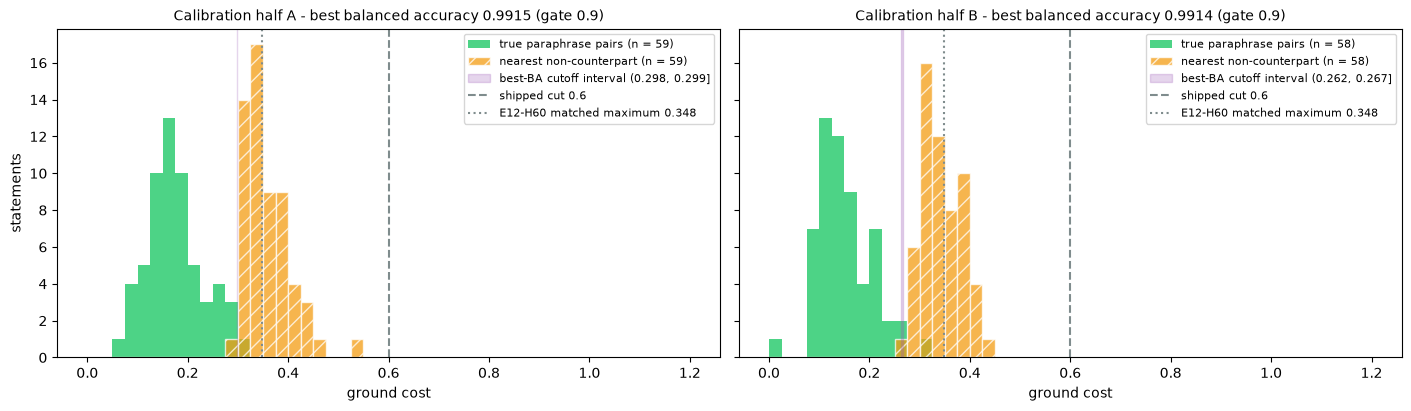

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True, sharey=True)
bins = np.linspace(0, 1.2, 49)
for ax, h in zip(axes, ("A", "B")):
    g = GATE[h]
    ax.hist(g["pair"], bins=bins, color=COLOR["pair"], alpha=0.85, label=f"true paraphrase pairs (n = {g['n']})")
    ax.hist(g["neighbour"], bins=bins, color=COLOR["neighbour"], alpha=0.75, hatch="//", edgecolor="white",
            label=f"nearest non-counterpart (n = {g['n']})")
    ax.axvspan(g["cutoff_low"], g["cutoff_high"], color=COLOR["cutoff"], alpha=0.25,
               label=f"best-BA cutoff interval ({g['cutoff_low']:.3f}, {g['cutoff_high']:.3f}]")
    ax.axvline(SHIPPED_CUT, color=COLOR["reference"], ls="--", lw=1.5, label=f"shipped cut {SHIPPED_CUT}")
    ax.axvline(E12_H60_MATCHED_MAX, color=COLOR["reference"], ls=":", lw=1.5,
               label=f"E12-H60 matched maximum {E12_H60_MATCHED_MAX}")
    ax.set_title(f"Calibration half {h} - best balanced accuracy {g['max']:.4f} (gate {GATE_BA_MIN})", fontsize=10)
    ax.set_xlabel("ground cost")
    ax.legend(fontsize=8)
axes[0].set_ylabel("statements")
plt.show()

## Labelled edit fixture

Built only when the gate passed. Document A is always the base document. Document B is the base with k
statements deleted, k donor statements inserted, or k statements replaced by donor statements at the same
position; its kept statements are either identical to A or their back-translations. A donor statement comes
from another base document of the same half, and a donor whose normalised text already occurs in the base is
left out of the pool, because two identical statements cannot be told apart by any labeller.

In [9]:
def norm_text(text: str) -> str:
    return " ".join(text.casefold().split())


def donor_relation(base: str, donor: str) -> str:
    # how the donor document relates to the base: the ibm documents summarise one article in parallel
    if ARTICLE[base] != ARTICLE[donor]:
        return "other article"
    return "sibling summary" if ARTICLE[base] == "ibm" else "other section"


def donor_pool(base: str) -> list[tuple[str, int]]:
    # (document, statement index) of every statement of the other bases in the same half, minus exact duplicates
    present = {norm_text(s) for s in BODY[base]}
    return [(d, i) for d in HALF_BASES[HALF_OF[base]] if d != base
            for i, s in enumerate(BODY[d]) if norm_text(s) not in present]


def build_edit(base: str, kind: str, k: int, rep: int, paraphrase: bool) -> dict:
    # one labelled pair; the generator ignores the paraphrase arm, so both arms share positions and donors
    rng = np.random.default_rng([SEED, zlib.crc32(f"{base}|{kind}|{k}|{rep}".encode())])
    n = len(BODY[base])
    removed = sorted(rng.choice(n, size=k, replace=False).tolist()) if kind != "insertion" else []
    pool = DONOR_POOL[base]
    donors = [pool[p] for p in rng.choice(len(pool), size=k, replace=False)] if kind != "deletion" else []
    slots = removed if kind == "replacement" else sorted(rng.integers(0, n + 1, size=len(donors)).tolist())
    inserted_at: dict[int, list[tuple[str, int]]] = {}
    for slot, donor in zip(slots, donors):
        inserted_at.setdefault(slot, []).append(donor)

    kept_text = BT_BODY[base] if paraphrase else BODY[base]
    b_text, y_b, relation, counterpart, replaced_by = [], [], [], np.full(n, -1), np.full(n, -1)
    for i in range(n + 1):  # position n is the end of the document
        for doc, index in inserted_at.get(i, []):
            if kind == "replacement":
                replaced_by[i] = len(b_text)
            b_text.append(BODY[doc][index])
            y_b.append(ADDED)
            relation.append(donor_relation(base, doc))
        if i < n and i not in removed:
            counterpart[i] = len(b_text)
            b_text.append(kept_text[i])
            y_b.append(KEPT)
            relation.append("")
    y_a = np.full(n, KEPT)
    y_a[removed] = REMOVED
    return {"pid": f"{base}|{kind}|{k}|{rep}|{'bt' if paraphrase else 'id'}", "base": base, "kind": kind, "k": k,
            "paraphrase": paraphrase, "a_text": BODY[base], "b_text": b_text, "y_a": y_a, "y_b": np.array(y_b),
            "counterpart": counterpart, "replaced_by": replaced_by, "relation": relation}


EDITS = []
if GATE_PASSED:
    DONOR_POOL = {b: donor_pool(b) for b in BASES}
    EDITS = [build_edit(b, kind, k, rep, paraphrase) for b in BASES for kind in EDIT_KINDS for k in EDIT_KS
             for rep in range(REPS) for paraphrase in PARAPHRASE_ARMS]
    duplicates_left_out = {b: sum(len(BODY[d]) for d in HALF_BASES[HALF_OF[b]] if d != b) - len(DONOR_POOL[b])
                           for b in BASES}

    t = Table(title=f"Labelled edit fixture - {len(EDITS)} pairs", title_style="bold cyan")
    for column in ("half", "kind", "pairs", "A statements", "B statements", "kept (A side)", "removed",
                   "kept (B side)", "added", "added from a sibling summary", "added from another article or section"):
        t.add_column(column, justify="left" if column in ("half", "kind") else "right")
    for h in ("A", "B"):
        for kind in EDIT_KINDS:
            sub = [e for e in EDITS if HALF_OF[e["base"]] == h and e["kind"] == kind]
            relations = [r for e in sub for r in e["relation"] if r]
            t.add_row(h, kind, str(len(sub)), str(sum(e["y_a"].size for e in sub)), str(sum(e["y_b"].size for e in sub)),
                      str(sum(int((e["y_a"] == KEPT).sum()) for e in sub)),
                      str(sum(int((e["y_a"] == REMOVED).sum()) for e in sub)),
                      str(sum(int((e["y_b"] == KEPT).sum()) for e in sub)),
                      str(sum(int((e["y_b"] == ADDED).sum()) for e in sub)),
                      str(relations.count("sibling summary")), str(len(relations) - relations.count("sibling summary")))
    console.print(t)
    print(f"donor statements left out of a pool because their text already occurs in the base: {duplicates_left_out}")
else:
    console.print(Panel("Skipped - the kill-gate fired, no edit fixture is built", border_style="red"))

                                                          Labelled edit fixture - 900 pairs                                                           
┏━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃      ┃             ┃       ┃              ┃              ┃               ┃         ┃               ┃       ┃                   ┃        added from ┃
┃      ┃             ┃       ┃              ┃              ┃               ┃         ┃               ┃       ┃      added from a ┃   another article ┃
┃ half ┃ kind        ┃ pairs ┃ A statements ┃ B statements ┃ kept (A side) ┃ removed ┃ kept (B side) ┃ added ┃   sibling summary ┃        or section ┃
┡━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ A    │ deletion    │   150 │         1770 │         1470 │          1470 │     300 │          1470 │     0 │                 0 │                 0 │
│ A    │ insertion   │   150 │         1770 │         2070 │          1770 │       0 │          1770 │   300 │               170 │               130 │
│ A    │ replacement │   150 │         1770 │         1770 │          1470 │     300 │          1470 │   300 │               160 │               140 │
│ B    │ deletion    │   150 │         1740 │         1440 │          1440 │     300 │          1440 │     0 │                 0 │                 0 │
│ B    │ insertion   │   150 │         1740 │         2040 │          1740 │       0 │          1740 │   300 │                88 │               212 │
│ B    │ replacement │   150 │         1740 │         1740 │          1440 │     300 │          1440 │   300 │                88 │               212 │
└──────┴─────────────┴───────┴──────────────┴──────────────┴───────────────┴─────────┴───────────────┴───────┴───────────────────┴───────────────────┘

donor statements left out of a pool because their text already occurs in the base: {'gold': 0, 'gold-2': 0, 'v1': 0, 'v2': 0, 'opus': 0, 'sonnet': 0, 'haiku': 0, 'werg-a': 0, 'werg-b': 0, 'werg-c': 0}


## Execution - shipped details on every edited pair

One `DocDistance.semantic_distance_with_details` call per edited pair gives the shipped flags. The instance's
`embed_statements` is wrapped for the duration of the loop so the embeddings of that same call are kept: the
cost matrix of the partial matching is then the shipped `cost_matrix` on exactly the vectors the shipped flags
were computed from. The labels are defined per constructed statement, so when SaT splits a statement differently
inside an edited text the call is repeated with the segmenter pinned to one statement per paragraph; those pairs
are counted and a secondary reading scores the pairs on the unmodified segmentation alone. Readings are
checkpointed every 100 pairs and read back on a re-run.

In [10]:
CAPTURED: list[tuple[list[str], np.ndarray]] = []


def recording_embed(doc, **kwargs):
    # the shipped embed_statements, with its return value also kept for the cost matrix
    out = DocDistance.embed_statements(DD, doc, **kwargs)
    CAPTURED.append(out)
    return out


class ParagraphSegmenter:
    # stand-in for the SaT segmenter: one statement per paragraph, the unit the labels are defined on
    @staticmethod
    def split(text: str) -> list[str]:
        return text.split("\n\n")


def details_call(edit: dict) -> tuple:
    # the shipped details call, its two embedding arrays, and whether the statements are the constructed ones
    CAPTURED.clear()
    result, details = DD.semantic_distance_with_details(join(edit["a_text"]), join(edit["b_text"]))
    (seg_a, emb_a), (seg_b, emb_b) = CAPTURED
    return result, details, emb_a, emb_b, seg_a == edit["a_text"] and seg_b == edit["b_text"]


def shipped_reading(edit: dict) -> dict:
    # the shipped details call on one edited pair, reduced to what the two labellers read
    result, details, emb_a, emb_b, exact = details_call(edit)
    if not exact:  # SaT split a statement differently inside the edited text: repeat with the statement units pinned
        sat, DD._segmenter = DD._segmenter, ParagraphSegmenter
        result, details, emb_a, emb_b, pinned_exact = details_call(edit)
        DD._segmenter = sat
        assert pinned_exact, edit["pid"]
    return {
        "shipped_segmentation": exact,
        "smd": result.smd,
        "cost": cost_matrix(emb_a, emb_b).astype(np.float64).tolist(),
        "no_counterpart": [flow["no_counterpart"] for flow in details["flows"]],
        "heaviest_target": [flow["matches"][0]["target_index"] for flow in details["flows"]],
        "n_targets": [len(flow["matches"]) for flow in details["flows"]],
        "min_incoming_cost": [target["min_incoming_cost"] for target in details["targets"]],
    }


def save_checkpoint(path: Path, readings: dict) -> None:
    scratch = path.with_suffix(".tmp")
    scratch.write_text(json.dumps(readings))
    scratch.replace(path)


READINGS, N_RESTORED, N_COMPUTED = {}, 0, 0
if GATE_PASSED:
    # the checkpoint is keyed by the library version and the exact texts, so a changed fixture never reads it
    fixture_key = hashlib.sha1(json.dumps([pipe._VERSION, [(e["pid"], e["a_text"], e["b_text"]) for e in EDITS]])
                               .encode()).hexdigest()[:12]
    CHECKPOINT = CHECKPOINT_DIR / f"shipped-readings-{len(EDITS):05d}-{fixture_key}.json"
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    if CHECKPOINT.exists():
        READINGS = json.loads(CHECKPOINT.read_text())
    N_RESTORED = len(READINGS)
    todo = [e for e in EDITS if e["pid"] not in READINGS]
    DD.embed_statements = recording_embed
    for done, edit in enumerate(progress(todo, "shipped details per edited pair"), start=1):
        READINGS[edit["pid"]] = shipped_reading(edit)
        if done % CHECKPOINT_EVERY == 0:
            save_checkpoint(CHECKPOINT, READINGS)
    del DD.embed_statements  # removes the instance override; the class method is in force again
    N_COMPUTED = len(todo)
    save_checkpoint(CHECKPOINT, READINGS)

shipped details per edited pair:   0%|          | 0/900 [00:00<?, ?it/s]

shipped details per edited pair:   3%|▎         | 30/900 [00:10<04:51,  2.98it/s]

shipped details per edited pair:   8%|▊         | 69/900 [00:20<03:57,  3.50it/s]

shipped details per edited pair:  12%|█▏        | 112/900 [00:30<03:24,  3.85it/s]

shipped details per edited pair:  17%|█▋        | 155/900 [00:41<03:13,  3.84it/s]

...

shipped details per edited pair:  77%|███████▋  | 695/900 [02:36<00:39,  5.17it/s]

shipped details per edited pair:  84%|████████▍ | 759/900 [02:46<00:25,  5.52it/s]

shipped details per edited pair:  91%|█████████▏| 823/900 [02:57<00:13,  5.59it/s]

shipped details per edited pair:  98%|█████████▊| 882/900 [03:07<00:03,  5.66it/s]

shipped details per edited pair: 100%|██████████| 900/900 [03:11<00:00,  4.71it/s]


In [11]:
PAIRS, N_PINNED = [], 0
if GATE_PASSED:
    for row, edit in enumerate(EDITS):
        reading = READINGS[edit["pid"]]
        pair = {**edit, "row": row, "shipped_segmentation": reading["shipped_segmentation"],
                "cost": np.array(reading["cost"]), "no_counterpart": np.array(reading["no_counterpart"]),
                "heaviest_target": np.array(reading["heaviest_target"]), "n_targets": np.array(reading["n_targets"]),
                "min_incoming_cost": np.array(reading["min_incoming_cost"]), "smd": reading["smd"]}
        assert pair["cost"].shape == (pair["y_a"].size, pair["y_b"].size)
        PAIRS.append(pair)
    N_PINNED = sum(not p["shipped_segmentation"] for p in PAIRS)
    pinned_by_arm = {("back-translated" if arm else "identical"): sum(
        not p["shipped_segmentation"] for p in PAIRS if p["paraphrase"] == arm) for arm in PARAPHRASE_ARMS}
    print(f"shipped details: {N_COMPUTED} pairs computed in this execution, {N_RESTORED} restored from "
          f"{CHECKPOINT_DIR.name}/{CHECKPOINT.name}\n"
          f"pairs scored: {len(PAIRS)} of {len(EDITS)}\n"
          f"pairs on the unmodified shipped segmentation: {len(PAIRS) - N_PINNED}; pairs where SaT split a statement "
          f"differently inside the edited text and the statement units were pinned: {N_PINNED} {pinned_by_arm}\n"
          f"instance overrides removed: {'embed_statements' not in vars(DD) and type(DD._segmenter).__name__ == 'Segmenter'}")
else:
    console.print(Panel("Skipped - the kill-gate fired", border_style="red"))

shipped details: 900 pairs computed in this execution, 0 restored from E13-H71/shipped-readings-00900-3e396129ed50.json
pairs scored: 900 of 900
pairs on the unmodified shipped segmentation: 863; pairs where SaT split a statement differently inside the edited text and the statement units were pinned: 37 {'identical': 4, 'back-translated': 33}
instance overrides removed: True


## Calibration and held-out scoring

Both labellers are scored on the same statements. The partial matching is swept over the cutoff grid once per
pair; c is then chosen on the calibration half only and applied to the other half, in both directions. The
shipped baseline reads `no_counterpart` as removed and a target `min_incoming_cost` above 0.6 as added.

In [12]:
def partial_matching(cost: np.ndarray, cutoff: float) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    # one-to-one matching on min(cost, c): A labels, B labels and the matched B index per A statement (-1 = none)
    rows, cols = linear_sum_assignment(np.minimum(cost, cutoff))
    matched = cost[rows, cols] < cutoff
    target = np.full(cost.shape[0], -1)
    target[rows[matched]] = cols[matched]
    labels_b = np.full(cost.shape[1], ADDED)
    labels_b[cols[matched]] = KEPT
    return np.where(target >= 0, KEPT, REMOVED), labels_b, target


def shipped_flags(pair: dict) -> tuple[np.ndarray, np.ndarray]:
    # the shipped reading: removed = no_counterpart, added = target min_incoming_cost above the shipped cut
    return (np.where(pair["no_counterpart"], REMOVED, KEPT),
            np.where(pair["min_incoming_cost"] > SHIPPED_CUT, ADDED, KEPT))


def add_counts(counts: np.ndarray, pair: dict, labels_a: np.ndarray, labels_b: np.ndarray) -> None:
    # confusion counts, true class in rows and predicted class in columns, over both sides of the pair
    np.add.at(counts, (pair["y_a"], labels_a), 1)
    np.add.at(counts, (pair["y_b"], labels_b), 1)


def confusion(pairs: list[dict], labeller) -> np.ndarray:
    counts = np.zeros((3, 3), dtype=np.int64)
    for pair in pairs:
        add_counts(counts, pair, *labeller(pair)[:2])
    return counts


def scores(counts: np.ndarray) -> dict:
    # per-class precision, recall and F1 plus the macro-F1; an empty denominator scores 0
    tp = np.diag(counts).astype(float)
    predicted, actual = counts.sum(axis=0), counts.sum(axis=1)
    f1 = np.divide(2 * tp, predicted + actual, out=np.zeros(3), where=(predicted + actual) > 0)
    return {"precision": np.divide(tp, predicted, out=np.zeros(3), where=predicted > 0),
            "recall": np.divide(tp, actual, out=np.zeros(3), where=actual > 0),
            "f1": f1, "macro_f1": float(f1.mean())}


def longest_run(mask: np.ndarray) -> tuple[int, int]:
    # first and last index of the longest run of True values (the first run on a tie)
    best, start = (0, -1), None
    for index, flag in enumerate(np.append(mask, False)):
        if flag and start is None:
            start = index
        elif not flag and start is not None:
            if index - 1 - start > best[1] - best[0]:
                best = (start, index - 1)
            start = None
    return best


def pairs_of(bases: list[str]) -> list[dict]:
    return [p for p in PAIRS if p["base"] in bases]


def macro_f1_curve(pairs: list[dict]) -> np.ndarray:
    total = GRID_COUNTS[[p["row"] for p in pairs]].sum(axis=0)
    return np.array([scores(total[index])["macro_f1"] for index in range(len(C_GRID))])


def calibrated_cutoff(curve: np.ndarray) -> float:
    # midpoint of the longest run of grid points at the maximum calibration macro-F1
    first, last = longest_run(np.isclose(curve, curve.max(), atol=1e-12))
    return round(float((C_GRID[first] + C_GRID[last]) / 2), 4)


def bar_range(curve: np.ndarray) -> list[float]:
    # lowest and highest cutoff of the longest run of grid points with macro-F1 at or above the bar
    first, last = longest_run(curve >= BAR_MACRO_F1)
    return [float(C_GRID[first]), float(C_GRID[last])] if last >= first else []


def held_out(calibration: list[dict], scored: list[dict], cutoff: float | None = None) -> dict:
    # choose c on the calibration pairs (or take the given one) and score both labellers on the scored pairs
    curve = macro_f1_curve(calibration)
    c = calibrated_cutoff(curve) if cutoff is None else cutoff
    proposed = scores(confusion(scored, lambda p: partial_matching(p["cost"], c)))
    shipped = scores(confusion(scored, shipped_flags))
    return {"cutoff": c, "calibration_macro_f1": float(curve.max()), "calibration_bar_range": bar_range(curve),
            "n_pairs": len(scored), "n_statements": int(sum(p["y_a"].size + p["y_b"].size for p in scored)),
            "proposed": proposed, "shipped": shipped, "delta": proposed["macro_f1"] - shipped["macro_f1"]}


GRID_COUNTS = np.zeros((len(PAIRS), len(C_GRID), 3, 3), dtype=np.int64)
for pair in progress(PAIRS, "cutoff sweep per pair"):
    for index, cutoff in enumerate(C_GRID):
        add_counts(GRID_COUNTS[pair["row"], index], pair, *partial_matching(pair["cost"], cutoff)[:2])
print(f"cutoff sweep: {len(PAIRS)} pairs x {len(C_GRID)} cutoffs")

cutoff sweep per pair:   0%|          | 0/900 [00:00<?, ?it/s]

cutoff sweep: 900 pairs x 191 cutoffs


cutoff sweep per pair: 100%|██████████| 900/900 [00:02<00:00, 414.39it/s]


In [13]:
HELD_OUT, SECONDARY, FIXED = {}, {}, {}
if GATE_PASSED:
    for calibration, scored in DIRECTIONS:
        HELD_OUT[(calibration, scored)] = held_out(pairs_of(HALF_BASES[calibration]), pairs_of(HALF_BASES[scored]))

    t = Table(title="Held-out scoring - c chosen on the calibration half, applied to the scored half",
              title_style="bold cyan")
    for column in ("direction", "c", "calibration macro-F1", "scored pairs", "scored statements", "labeller",
                   "macro-F1", "F1 kept", "F1 removed", "F1 added", "gain over shipped",
                   f">= {BAR_MACRO_F1} and >= +{BAR_DELTA}"):
        t.add_column(column, justify="left" if column in ("direction", "labeller") else "right")
    for (calibration, scored), r in HELD_OUT.items():
        met = r["proposed"]["macro_f1"] >= BAR_MACRO_F1 and r["delta"] >= BAR_DELTA
        for labeller in ("proposed", "shipped"):
            s = r[labeller]
            first = labeller == "proposed"
            t.add_row(f"{calibration} → {scored}" if first else "", f"{r['cutoff']:.4f}" if first else "",
                      f"{r['calibration_macro_f1']:.4f}" if first else "", str(r["n_pairs"]) if first else "",
                      str(r["n_statements"]) if first else "",
                      "partial matching" if first else "shipped flags", f"{s['macro_f1']:.4f}",
                      *[f"{v:.4f}" for v in s["f1"]], f"{r['delta']:+.4f}" if first else "",
                      ("[green]met[/green]" if met else "[red]NOT MET[/red]") if first else "",
                      style=f"bold {COLOR['proposed']}" if first else COLOR["shipped"])
    console.print(t)

    t = Table(title="Precision and recall per class on the scored half", title_style="bold cyan")
    for column in ("direction", "labeller", *[f"{m} {c}" for c in CLASS_NAMES for m in ("precision", "recall")]):
        t.add_column(column, justify="left" if column in ("direction", "labeller") else "right")
    for (calibration, scored), r in HELD_OUT.items():
        for labeller, label in (("proposed", "partial matching"), ("shipped", "shipped flags")):
            s = r[labeller]
            t.add_row(f"{calibration} → {scored}", label,
                      *[f"{s[m][k]:.4f}" for k in range(3) for m in ("precision", "recall")])
    console.print(t)
    print("cutoff range with calibration macro-F1 at or above the bar: " + "; ".join(
        f"half {calibration} [{r['calibration_bar_range'][0]:.3f}, {r['calibration_bar_range'][1]:.3f}]"
        for (calibration, _), r in HELD_OUT.items()))

    # secondary readings, not part of the bar: another way to arrive at a cutoff, the pairs on the unmodified
    # segmentation alone, and a split by article
    ibm = pairs_of([b for b in BASES if ARTICLE[b] == "ibm"])
    wergeland = pairs_of([b for b in BASES if ARTICLE[b] != "ibm"])
    for calibration, scored in DIRECTIONS:
        SECONDARY[f"population cutoff, half {calibration} → half {scored}"] = held_out(
            pairs_of(HALF_BASES[calibration]), pairs_of(HALF_BASES[scored]),
            cutoff=round(GATE[calibration]["cutoff_mid"], 4))
    for calibration, scored in DIRECTIONS:
        SECONDARY[f"shipped segmentation only, half {calibration} → half {scored}"] = held_out(
            [p for p in pairs_of(HALF_BASES[calibration]) if p["shipped_segmentation"]],
            [p for p in pairs_of(HALF_BASES[scored]) if p["shipped_segmentation"]])
    SECONDARY["article split, ibm → wergeland"] = held_out(ibm, wergeland)
    SECONDARY["article split, wergeland → ibm"] = held_out(wergeland, ibm)
    SECONDARY["in-sample, all bases → all bases"] = held_out(PAIRS, PAIRS)

    t = Table(title="Secondary readings - not part of the acceptance bar", title_style="bold cyan")
    for column in ("reading", "c", "scored pairs", "partial matching macro-F1", "F1 kept", "F1 removed", "F1 added",
                   "shipped macro-F1", "gain"):
        t.add_column(column, justify="left" if column == "reading" else "right")
    for name, r in SECONDARY.items():
        t.add_row(name, f"{r['cutoff']:.4f}", str(r["n_pairs"]), f"{r['proposed']['macro_f1']:.4f}",
                  *[f"{v:.4f}" for v in r["proposed"]["f1"]], f"{r['shipped']['macro_f1']:.4f}", f"{r['delta']:+.4f}")
    console.print(t)

    # the same curves read at fixed cutoffs: how far the score moves when the cutoff is not the calibrated one
    curves = {name: macro_f1_curve(pairs) for name, pairs in (("half_A", pairs_of(HALF_BASES["A"])),
                                                              ("half_B", pairs_of(HALF_BASES["B"])), ("all", PAIRS))}
    FIXED = {f"{c:.3f}": {name: round(float(curve[np.flatnonzero(np.isclose(C_GRID, c))[0]]), 4)
                          for name, curve in curves.items()} for c in FIXED_CUTOFFS}
    t = Table(title="Macro-F1 at fixed cutoffs - read off the curve of each half, no cutoff chosen",
              title_style="bold cyan")
    for column in ("cutoff", "half A", "half B", "all pairs", f"both halves >= {BAR_MACRO_F1}"):
        t.add_column(column, justify="right")
    for c, r in FIXED.items():
        both = min(r["half_A"], r["half_B"]) >= BAR_MACRO_F1
        t.add_row(c, f"{r['half_A']:.4f}", f"{r['half_B']:.4f}", f"{r['all']:.4f}",
                  "[green]yes[/green]" if both else "[red]no[/red]")
    console.print(t)
else:
    console.print(Panel("Skipped - the kill-gate fired", border_style="red"))

                                   Held-out scoring - c chosen on the calibration half, applied to the scored half                                    
┏━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃           ┃        ┃ calibration ┃      scored ┃      scored ┃             ┃          ┃         ┃            ┃          ┃  gain over ┃  >= 0.9 and ┃
┃ direction ┃      c ┃    macro-F1 ┃       pairs ┃  statements ┃ labeller    ┃ macro-F1 ┃ F1 kept ┃ F1 removed ┃ F1 added ┃    shipped ┃     >= +0.3 ┃
┡━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ A → B     │ 0.3250 │      0.9674 │         450 │       10440 │ partial     │   0.9772 │  0.9959 │     0.9831 │   0.9525 │    +0.6642 │         met │
│           │        │             │             │             │ matching    │          │         │            │          │            │             │
│           │        │             │             │             │ shipped     │   0.3130 │  0.9390 │     0.0000 │   0.0000 │            │             │
│           │        │             │             │             │ flags       │          │         │            │          │            │             │
│ B → A     │ 0.3100 │      0.9790 │         450 │       10620 │ partial     │   0.9457 │  0.9901 │     0.9441 │   0.9030 │    +0.6191 │         met │
│           │        │             │             │             │ matching    │          │         │            │          │            │             │
│           │        │             │             │             │ shipped     │   0.3266 │  0.9407 │     0.0000 │   0.0392 │            │             │
│           │        │             │             │             │ flags       │          │         │            │          │            │             │
└───────────┴────────┴─────────────┴─────────────┴─────────────┴─────────────┴──────────┴─────────┴────────────┴──────────┴────────────┴─────────────┘

                                          Precision and recall per class on the scored half                                          
┏━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ direction ┃ labeller         ┃ precision kept ┃ recall kept ┃ precision removed ┃ recall removed ┃ precision added ┃ recall added ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ A → B     │ partial matching │         0.9938 │      0.9981 │            1.0000 │         0.9667 │          0.9690 │       0.9367 │
│ A → B     │ shipped flags    │         0.8851 │      1.0000 │            0.0000 │         0.0000 │          0.0000 │       0.0000 │
│ B → A     │ partial matching │         0.9918 │      0.9884 │            0.9318 │         0.9567 │          0.8912 │       0.9150 │
│ B → A     │ shipped flags    │         0.8880 │      1.0000 │            0.0000 │         0.0000 │          1.0000 │       0.0200 │
└───────────┴──────────────────┴────────────────┴─────────────┴───────────────────┴────────────────┴─────────────────┴──────────────┘

cutoff range with calibration macro-F1 at or above the bar: half A [0.280, 0.440]; half B [0.240, 0.455]


                                                 Secondary readings - not part of the acceptance bar                                                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ reading                         ┃      c ┃ scored pairs ┃ partial matching macro-F1 ┃ F1 kept ┃ F1 removed ┃ F1 added ┃ shipped macro-F1 ┃    gain ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ population cutoff, half A →     │ 0.2984 │          450 │                    0.9593 │  0.9924 │     0.9583 │   0.9272 │           0.3130 │ +0.6463 │
│ half B                          │        │              │                           │         │            │          │                  │         │
│ population cutoff, half B →     │ 0.2647 │          450 │                    0.8461 │  0.9661 │     0.8033 │   0.7689 │           0.3266 │ +0.5195 │
│ half A                          │        │              │                           │         │            │          │                  │         │
│ shipped segmentation only, half │ 0.3250 │          444 │                    0.9773 │  0.9960 │     0.9835 │   0.9525 │           0.3132 │ +0.6641 │
│ A → half B                      │        │              │                           │         │            │          │                  │         │
│ shipped segmentation only, half │ 0.3100 │          419 │                    0.9467 │  0.9903 │     0.9431 │   0.9067 │           0.3278 │ +0.6189 │
│ B → half A                      │        │              │                           │         │            │          │                  │         │
│ article split, ibm → wergeland  │ 0.3250 │          270 │                    1.0000 │  1.0000 │     1.0000 │   1.0000 │           0.3295 │ +0.6705 │
│ article split, wergeland → ibm  │ 0.2950 │          630 │                    0.9185 │  0.9839 │     0.9108 │   0.8609 │           0.3156 │ +0.6029 │
│ in-sample, all bases → all      │ 0.3250 │          900 │                    0.9723 │  0.9951 │     0.9792 │   0.9426 │           0.3199 │ +0.6524 │
│ bases                           │        │              │                           │         │            │          │                  │         │
└─────────────────────────────────┴────────┴──────────────┴───────────────────────────┴─────────┴────────────┴──────────┴──────────────────┴─────────┘

Macro-F1 at fixed cutoffs - read off the curve of each half, 
                      no cutoff chosen                       
┏━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ cutoff ┃ half A ┃ half B ┃ all pairs ┃ both halves >= 0.9 ┃
┡━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│  0.280 │ 0.9087 │ 0.9593 │    0.9333 │                yes │
│  0.300 │ 0.9470 │ 0.9593 │    0.9531 │                yes │
│  0.310 │ 0.9457 │ 0.9790 │    0.9621 │                yes │
│  0.325 │ 0.9674 │ 0.9772 │    0.9723 │                yes │
│  0.350 │ 0.9538 │ 0.9665 │    0.9602 │                yes │
│  0.400 │ 0.9287 │ 0.9441 │    0.9364 │                yes │
│  0.440 │ 0.9027 │ 0.9167 │    0.9098 │                yes │
│  0.500 │ 0.8691 │ 0.8492 │    0.8593 │                 no │
│  0.600 │ 0.7828 │ 0.7713 │    0.7771 │                 no │
└────────┴────────┴────────┴───────────┴────────────────────┘

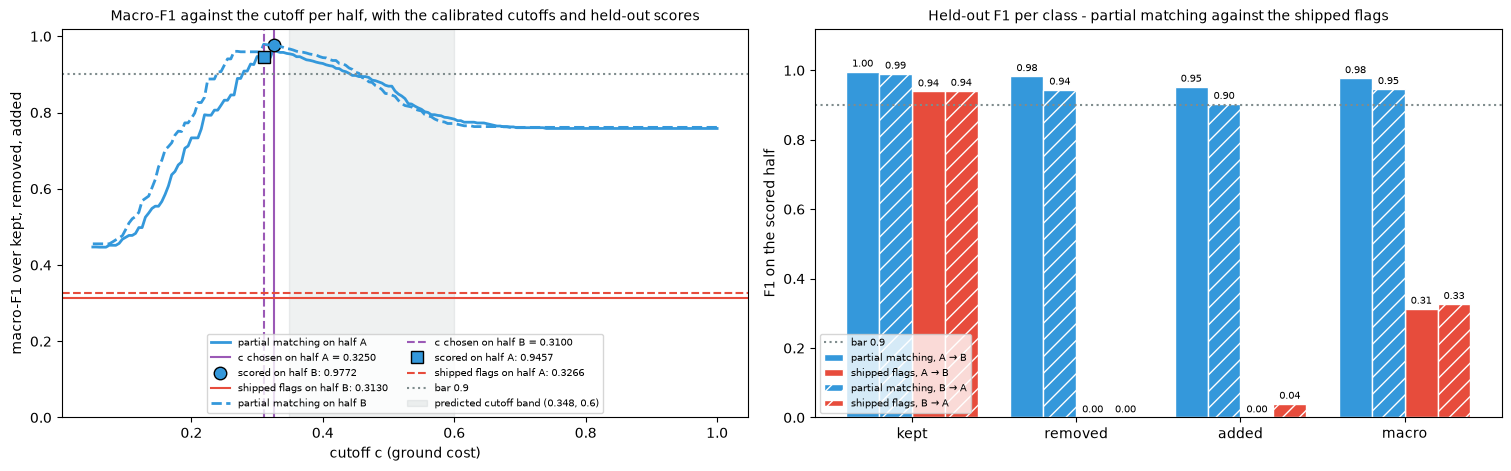

In [14]:
if GATE_PASSED:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), constrained_layout=True)

    ax = axes[0]
    for (calibration, scored), style, marker in zip(DIRECTIONS, ("-", "--"), ("o", "s")):
        r = HELD_OUT[(calibration, scored)]
        ax.plot(C_GRID, macro_f1_curve(pairs_of(HALF_BASES[calibration])), color=COLOR["proposed"], ls=style, lw=2,
                label=f"partial matching on half {calibration}")
        ax.axvline(r["cutoff"], color=COLOR["cutoff"], ls=style, lw=1.5,
                   label=f"c chosen on half {calibration} = {r['cutoff']:.4f}")
        ax.plot(r["cutoff"], r["proposed"]["macro_f1"], marker=marker, ms=9, color=COLOR["proposed"],
                markeredgecolor="black", ls="none",
                label=f"scored on half {scored}: {r['proposed']['macro_f1']:.4f}")
        ax.axhline(r["shipped"]["macro_f1"], color=COLOR["shipped"], ls=style, lw=1.5,
                   label=f"shipped flags on half {scored}: {r['shipped']['macro_f1']:.4f}")
    ax.axhline(BAR_MACRO_F1, color=COLOR["reference"], ls=":", lw=1.5, label=f"bar {BAR_MACRO_F1}")
    ax.axvspan(E12_H60_MATCHED_MAX, SHIPPED_CUT, color=COLOR["reference"], alpha=0.12,
               label=f"predicted cutoff band ({E12_H60_MATCHED_MAX}, {SHIPPED_CUT})")
    ax.set_xlabel("cutoff c (ground cost)")
    ax.set_ylabel("macro-F1 over kept, removed, added")
    ax.set_ylim(0, 1.02)
    ax.set_title("Macro-F1 against the cutoff per half, with the calibrated cutoffs and held-out scores", fontsize=10)
    ax.legend(fontsize=7, loc="lower center", ncol=2)

    ax = axes[1]
    names = [*CLASS_NAMES, "macro"]
    width = 0.2
    x = np.arange(len(names))
    for offset, ((calibration, scored), hatch) in enumerate(zip(DIRECTIONS, ("", "//"))):
        r = HELD_OUT[(calibration, scored)]
        for shift, labeller, label in ((0, "proposed", "partial matching"), (2, "shipped", "shipped flags")):
            values = [*r[labeller]["f1"], r[labeller]["macro_f1"]]
            bars = ax.bar(x + (offset + shift - 1.5) * width, values, width, color=COLOR[labeller], hatch=hatch,
                          edgecolor="white", label=f"{label}, {calibration} → {scored}")
            ax.bar_label(bars, labels=[f"{v:.2f}" for v in values], fontsize=7, padding=2)
    ax.axhline(BAR_MACRO_F1, color=COLOR["reference"], ls=":", lw=1.5, label=f"bar {BAR_MACRO_F1}")
    ax.set_xticks(x, names)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("F1 on the scored half")
    ax.set_title("Held-out F1 per class - partial matching against the shipped flags", fontsize=10)
    ax.legend(fontsize=7, loc="lower left")
    plt.show()

## Per-condition and mechanism readings

Every pair is labelled once with the cutoff chosen on the other half, so the tables below pool held-out
predictions only. They locate where each labeller fails (edit kind, paraphrase arm, base document, donor
relation) and test the two mechanism claims of the record: the balanced plan splits statements across targets
when lengths differ, and a removed statement lands on a neighbour below the 0.6 cut.

In [15]:
ERROR_TYPES = (("kept read as removed", "a", KEPT, REMOVED), ("removed read as kept", "a", REMOVED, KEPT),
               ("kept read as added", "b", KEPT, ADDED), ("added read as kept", "b", ADDED, KEPT))


def rate(hits: int, total: int) -> str:
    return f"{hits}/{total} = {hits / total:.4f}" if total else "-"


def count(pairs: list[dict], side: str, truth: int, predicted: int, labeller: str) -> int:
    # statements of one side with the given true class that the labeller put in the predicted class
    return int(sum(((p[f"y_{side}"] == truth) & (p[f"{labeller}_{side}"] == predicted)).sum() for p in pairs))


CONDITIONS, PER_BASE, MECHANISM = [], {}, {}
if GATE_PASSED:
    cutoff_for_base = {b: HELD_OUT[(calibration, scored)]["cutoff"]
                       for calibration, scored in DIRECTIONS for b in HALF_BASES[scored]}
    for pair in PAIRS:
        pair["pm_a"], pair["pm_b"], pair["pm_target"] = partial_matching(pair["cost"], cutoff_for_base[pair["base"]])
        pair["sh_a"], pair["sh_b"] = shipped_flags(pair)

    for kind in EDIT_KINDS:
        for paraphrase in PARAPHRASE_ARMS:
            sub = [p for p in PAIRS if p["kind"] == kind and p["paraphrase"] == paraphrase]
            n_statements = sum(p["y_a"].size + p["y_b"].size for p in sub)
            n_removed = sum(int((p["y_a"] == REMOVED).sum()) for p in sub)
            n_added = sum(int((p["y_b"] == ADDED).sum()) for p in sub)
            row = {"kind": kind, "paraphrase": paraphrase, "n_pairs": len(sub), "n_statements": int(n_statements),
                   "n_removed": n_removed, "n_added": n_added}
            for labeller in ("pm", "sh"):
                errors = sum(int((p[f"{labeller}_a"] != p["y_a"]).sum() + (p[f"{labeller}_b"] != p["y_b"]).sum())
                             for p in sub)
                row[labeller] = {"errors": errors, "error_rate": errors / n_statements,
                                 "removed_found": count(sub, "a", REMOVED, REMOVED, labeller),
                                 "added_found": count(sub, "b", ADDED, ADDED, labeller),
                                 **{name: count(sub, side, truth, predicted, labeller)
                                    for name, side, truth, predicted in ERROR_TYPES}}
            CONDITIONS.append(row)

    t = Table(title="Held-out label errors per edit condition (both directions pooled)", title_style="bold cyan")
    for column in ("kind", "kept statements", "pairs", "statements", "labeller", "label errors", "error rate",
                   "removed found", "added found", *[name for name, *_ in ERROR_TYPES]):
        t.add_column(column, justify="left" if column in ("kind", "kept statements", "labeller") else "right")
    for row in CONDITIONS:
        for labeller, label in (("pm", "partial matching"), ("sh", "shipped flags")):
            s, first = row[labeller], labeller == "pm"
            t.add_row(row["kind"] if first else "", ("back-translated" if row["paraphrase"] else "identical") if first else "",
                      str(row["n_pairs"]) if first else "", str(row["n_statements"]) if first else "", label,
                      str(s["errors"]), f"{s['error_rate']:.4f}", rate(s["removed_found"], row["n_removed"]),
                      rate(s["added_found"], row["n_added"]), *[str(s[name]) for name, *_ in ERROR_TYPES],
                      style=f"bold {COLOR['proposed']}" if first else COLOR["shipped"])
    console.print(t)

    for b in BASES:
        sub = [p for p in PAIRS if p["base"] == b]
        PER_BASE[b] = {"cutoff": cutoff_for_base[b],
                       "proposed": scores(confusion(sub, lambda p: (p["pm_a"], p["pm_b"])))["macro_f1"],
                       "shipped": scores(confusion(sub, shipped_flags))["macro_f1"],
                       "kept_read_as_removed_or_added": count(sub, "a", KEPT, REMOVED, "pm") + count(sub, "b", KEPT, ADDED, "pm"),
                       "removed_or_added_read_as_kept": count(sub, "a", REMOVED, KEPT, "pm") + count(sub, "b", ADDED, KEPT, "pm"),
                       "largest_pair_cost": float(np.diag(PAIR_COST[b]).max())}
    t = Table(title="Held-out macro-F1 per scored base document", title_style="bold cyan")
    for column in ("base", "article", "half", "c applied", "largest pair cost", "partial matching", "shipped flags",
                   "gain", "kept read as removed or added", "removed or added read as kept"):
        t.add_column(column, justify="left" if column in ("base", "article", "half") else "right")
    for b in BASES:
        r = PER_BASE[b]
        below = r["proposed"] < BAR_MACRO_F1
        t.add_row(b, ARTICLE[b], HALF_OF[b], f"{r['cutoff']:.4f}", f"{r['largest_pair_cost']:.4f}",
                  f"[red]{r['proposed']:.4f}[/red]" if below else f"{r['proposed']:.4f}", f"{r['shipped']:.4f}",
                  f"{r['proposed'] - r['shipped']:+.4f}", str(r["kept_read_as_removed_or_added"]),
                  str(r["removed_or_added_read_as_kept"]))
    console.print(t)
else:
    console.print(Panel("Skipped - the kill-gate fired", border_style="red"))

                                          Held-out label errors per edit condition (both directions pooled)                                           
┏━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┓
┃           ┃           ┃       ┃           ┃           ┃           ┃           ┃          ┃           ┃     kept ┃   removed ┃     kept ┃     added ┃
┃           ┃ kept      ┃       ┃           ┃           ┃     label ┃     error ┃  removed ┃     added ┃  read as ┃   read as ┃  read as ┃   read as ┃
┃ kind      ┃ statemen… ┃ pairs ┃ statemen… ┃ labeller  ┃    errors ┃      rate ┃    found ┃     found ┃  removed ┃      kept ┃    added ┃      kept ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━┩
│ deletion  │ identical │   150 │      3210 │ partial   │         0 │    0.0000 │  300/300 │         - │        0 │         0 │        0 │         0 │
│           │           │       │           │ matching  │           │           │ = 1.0000 │           │          │           │          │           │
│           │           │       │           │ shipped   │       300 │    0.0935 │  0/300 = │         - │        0 │       300 │        0 │         0 │
│           │           │       │           │ flags     │           │           │   0.0000 │           │          │           │          │           │
│ deletion  │ back-tra… │   150 │      3210 │ partial   │        28 │    0.0087 │  300/300 │         - │       14 │         0 │       14 │         0 │
│           │           │       │           │ matching  │           │           │ = 1.0000 │           │          │           │          │           │
│           │           │       │           │ shipped   │       300 │    0.0935 │  0/300 = │         - │        0 │       300 │        0 │         0 │
│           │           │       │           │ flags     │           │           │   0.0000 │           │          │           │          │           │
│ insertion │ identical │   150 │      3810 │ partial   │         0 │    0.0000 │        - │ 300/300 = │        0 │         0 │        0 │         0 │
│           │           │       │           │ matching  │           │           │          │    1.0000 │          │           │          │           │
│           │           │       │           │ shipped   │       297 │    0.0780 │        - │   3/300 = │        0 │         0 │        0 │       297 │
│           │           │       │           │ flags     │           │           │          │    0.0100 │          │           │          │           │
│ insertion │ back-tra… │   150 │      3810 │ partial   │        70 │    0.0184 │        - │ 280/300 = │       15 │         0 │       35 │        20 │
│           │           │       │           │ matching  │           │           │          │    0.9333 │          │           │          │           │
│           │           │       │           │ shipped   │       297 │    0.0780 │        - │   3/300 = │        0 │         0 │        0 │       297 │
│           │           │       │           │ flags     │           │           │          │    0.0100 │          │           │          │           │
│ replacem… │ identical │   150 │      3510 │ partial   │        48 │    0.0137 │  276/300 │ 276/300 = │        0 │        24 │        0 │        24 │
│           │           │       │           │ matching  │           │           │ = 0.9200 │    0.9200 │          │           │          │           │
│           │           │[38;2;231;76;

                                                      Held-out macro-F1 per scored base document                                                      
┏━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃        ┃           ┃      ┃           ┃                   ┃                  ┃               ┃         ┃        kept read as ┃    removed or added ┃
┃ base   ┃ article   ┃ half ┃ c applied ┃ largest pair cost ┃ partial matching ┃ shipped flags ┃    gain ┃    removed or added ┃        read as kept ┃
┡━━━━━━━━╇━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ gold   │ ibm       │ A    │    0.3100 │            0.2886 │           0.9378 │        0.3095 │ +0.6283 │                  10 │                  30 │
│ gold-2 │ ibm       │ B    │    0.3250 │            0.2621 │           0.9421 │        0.3137 │ +0.6284 │                  11 │                  27 │
│ v1     │ ibm       │ A    │    0.3100 │            0.2136 │           0.9729 │        0.3118 │ +0.6610 │                   5 │                  13 │
│ v2     │ ibm       │ B    │    0.3250 │            0.3069 │           0.9635 │        0.3118 │ +0.6517 │                   6 │                  18 │
│ opus   │ ibm       │ A    │    0.3100 │            0.2978 │           0.9607 │        0.3355 │ +0.6252 │                   7 │                  19 │
│ sonnet │ ibm       │ B    │    0.3250 │            0.2352 │           0.9786 │        0.3095 │ +0.6690 │                   1 │                  13 │
│ haiku  │ ibm       │ A    │    0.3100 │            0.3229 │           0.8686 │        0.3153 │ +0.5533 │                  87 │                  15 │
│ werg-a │ wergeland │ B    │    0.3250 │            0.2220 │           1.0000 │        0.3118 │ +0.6882 │                   0 │                   0 │
│ werg-b │ wergeland │ A    │    0.3100 │            0.2562 │           1.0000 │        0.3576 │ +0.6424 │                   0 │                   0 │
│ werg-c │ wergeland │ B    │    0.3250 │            0.2186 │           1.0000 │        0.3167 │ +0.6833 │                   0 │                   0 │
└────────┴───────────┴──────┴───────────┴───────────────────┴──────────────────┴───────────────┴─────────┴─────────────────────┴─────────────────────┘

In [16]:
if GATE_PASSED:
    # shipped plan: targets per A statement, by edit kind (replacement keeps the lengths equal)
    MECHANISM["targets_per_statement"] = {
        kind: round(float(np.concatenate([p["n_targets"] for p in PAIRS if p["kind"] == kind]).mean()), 4)
        for kind in EDIT_KINDS}

    # truly kept A statements: does each labeller point at the true counterpart
    kept_total = sum(int((p["y_a"] == KEPT).sum()) for p in PAIRS)
    MECHANISM["kept_counterpart"] = {
        "n_kept": kept_total,
        "partial_matching_correct": int(sum(((p["y_a"] == KEPT) & (p["pm_target"] == p["counterpart"])).sum() for p in PAIRS)),
        "partial_matching_other_target": int(sum(((p["y_a"] == KEPT) & (p["pm_target"] >= 0)
                                                  & (p["pm_target"] != p["counterpart"])).sum() for p in PAIRS)),
        "partial_matching_unmatched": int(sum(((p["y_a"] == KEPT) & (p["pm_target"] < 0)).sum() for p in PAIRS)),
        "shipped_heaviest_correct": int(sum(((p["y_a"] == KEPT) & (p["heaviest_target"] == p["counterpart"])).sum() for p in PAIRS)),
    }

    # cheapest cost a removed statement finds in B, and an added statement finds in A - what the shipped cut reads
    removed_cost = np.concatenate([p["cost"][p["y_a"] == REMOVED].min(axis=1) for p in PAIRS if (p["y_a"] == REMOVED).any()])
    added_cost = np.concatenate([p["cost"][:, p["y_b"] == ADDED].min(axis=0) for p in PAIRS if (p["y_b"] == ADDED).any()])
    kept_cost = np.concatenate([p["cost"][np.flatnonzero(p["y_a"] == KEPT), p["counterpart"][p["y_a"] == KEPT]]
                                for p in PAIRS if p["paraphrase"]])
    MECHANISM["cheapest_cost"] = {
        "removed_statement_to_B": {"n": int(removed_cost.size), "above_shipped_cut": int((removed_cost > SHIPPED_CUT).sum()),
                                   "percentiles": percentiles(removed_cost)},
        "added_statement_to_A": {"n": int(added_cost.size), "above_shipped_cut": int((added_cost > SHIPPED_CUT).sum()),
                                 "percentiles": percentiles(added_cost)},
        "kept_back_translated_pair": {"n": int(kept_cost.size), "above_shipped_cut": int((kept_cost > SHIPPED_CUT).sum()),
                                      "percentiles": percentiles(kept_cost)},
    }

    # added statements found, by how the donor document relates to the base
    MECHANISM["added_by_donor_relation"] = {}
    for relation in ("sibling summary", "other section", "other article"):
        masks = [(p, np.array([r == relation for r in p["relation"]])) for p in PAIRS]
        total = int(sum(m.sum() for _, m in masks))
        MECHANISM["added_by_donor_relation"][relation] = {
            "n": total,
            "partial_matching_found": int(sum((p["pm_b"][m] == ADDED).sum() for p, m in masks)),
            "shipped_found": int(sum((p["sh_b"][m] == ADDED).sum() for p, m in masks)),
        }

    # a removed statement read as kept: which B statement did the matching give it
    swallowed = [(p, i) for p in PAIRS for i in np.flatnonzero((p["y_a"] == REMOVED) & (p["pm_a"] == KEPT))]
    MECHANISM["removed_read_as_kept"] = {
        "n": len(swallowed),
        "matched_to_an_added_statement": sum(int(p["y_b"][p["pm_target"][i]] == ADDED) for p, i in swallowed),
        "matched_to_a_kept_statement": sum(int(p["y_b"][p["pm_target"][i]] == KEPT) for p, i in swallowed),
    }

    # replacement edits: cost between a removed statement and the donor statement put in its place - the pairing
    # the cutoff has to refuse - split by how the donor document relates to the base
    MECHANISM["replacement_pair_cost"] = {}
    replaced = [(p, i, p["replaced_by"][i]) for p in PAIRS for i in np.flatnonzero(p["replaced_by"] >= 0)]
    for group, sibling in (("sibling summary", True), ("other article or section", False)):
        rows = [(p["cost"][i, j], cutoff_for_base[p["base"]]) for p, i, j in replaced
                if (p["relation"][j] == "sibling summary") == sibling]
        costs, cutoffs = (np.array(column) for column in zip(*rows))
        MECHANISM["replacement_pair_cost"][group] = {
            "n": int(costs.size), "below_applied_cutoff": int((costs < cutoffs).sum()), "percentiles": percentiles(costs)}

    # no-edit control: the unedited base against its own back-translation, labelled with the cutoff of its direction
    no_edit = {b: int((partial_matching(PAIR_COST[b], cutoff_for_base[b])[0] == REMOVED).sum()) for b in BASES}
    MECHANISM["no_edit_control"] = {"n_statements": int(sum(PAIR_COST[b].shape[0] for b in BASES)),
                                    "read_as_removed": sum(no_edit.values()), "per_base": no_edit}

    spread = lambda q: (f"min {q['p0']:.4f} | p5 {q['p5']:.4f} | p25 {q['p25']:.4f} | p50 {q['p50']:.4f} | "
                        f"p75 {q['p75']:.4f} | p95 {q['p95']:.4f} | max {q['p100']:.4f}")
    k = MECHANISM["kept_counterpart"]
    c = MECHANISM["cheapest_cost"]
    w = MECHANISM["removed_read_as_kept"]
    n = MECHANISM["no_edit_control"]
    t = Table(title="Mechanism readings on the held-out predictions", title_style="bold cyan", show_lines=True)
    t.add_column("reading")
    t.add_column("value")
    t.add_row("shipped plan - mean targets per A statement",
              ", ".join(f"{kind} {v:.4f}" for kind, v in MECHANISM["targets_per_statement"].items()))
    t.add_row("kept A statements pointed at their true counterpart",
              f"partial matching {rate(k['partial_matching_correct'], k['n_kept'])} "
              f"(other target {k['partial_matching_other_target']}, unmatched {k['partial_matching_unmatched']})\n"
              f"shipped heaviest target {rate(k['shipped_heaviest_correct'], k['n_kept'])}")
    for name, label in (("removed_statement_to_B", "removed statement - cheapest cost in B"),
                        ("added_statement_to_A", "added statement - cheapest cost in A"),
                        ("kept_back_translated_pair", "kept statement - cost to its back-translation")):
        t.add_row(label, f"above the shipped cut {SHIPPED_CUT}: {rate(c[name]['above_shipped_cut'], c[name]['n'])}\n"
                         f"{spread(c[name]['percentiles'])}")
    for group, r in MECHANISM["replacement_pair_cost"].items():
        t.add_row(f"replacement - cost between the removed statement and its replacement, donor is {group}",
                  f"below the applied cutoff: {rate(r['below_applied_cutoff'], r['n'])}\n{spread(r['percentiles'])}")
    for relation, r in MECHANISM["added_by_donor_relation"].items():
        t.add_row(f"added statements found - donor is {relation}",
                  f"partial matching {rate(r['partial_matching_found'], r['n'])} | "
                  f"shipped flags {rate(r['shipped_found'], r['n'])}")
    t.add_row("removed statements read as kept by the partial matching",
              f"{w['n']} in total: {w['matched_to_an_added_statement']} matched to an added statement, "
              f"{w['matched_to_a_kept_statement']} matched to a kept statement")
    t.add_row("no-edit control - unedited base against its own back-translation",
              f"statements read as removed: {rate(n['read_as_removed'], n['n_statements'])} "
              f"(bases with one or more: {', '.join(f'{b} {v}' for b, v in n['per_base'].items() if v) or 'none'})")
    console.print(t)
else:
    console.print(Panel("Skipped - the kill-gate fired", border_style="red"))

                                                    Mechanism readings on the held-out predictions                                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ reading                                                                 ┃ value                                                                    ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ shipped plan - mean targets per A statement                             │ deletion 1.7179, insertion 2.0598, replacement 1.0000                    │
├─────────────────────────────────────────────────────────────────────────┼──────────────────────────────────────────────────────────────────────────┤
│ kept A statements pointed at their true counterpart                     │ partial matching 9244/9330 = 0.9908 (other target 44, unmatched 42)      │
│                                                                         │ shipped heaviest target 9286/9330 = 0.9953                               │
├─────────────────────────────────────────────────────────────────────────┼──────────────────────────────────────────────────────────────────────────┤
│ removed statement - cheapest cost in B                                  │ above the shipped cut 0.6: 0/1200 = 0.0000                               │
│                                                                         │ min 0.1738 | p5 0.2829 | p25 0.3140 | p50 0.3405 | p75 0.3820 | p95      │
│                                                                         │ 0.4339 | max 0.5455                                                      │
├─────────────────────────────────────────────────────────────────────────┼──────────────────────────────────────────────────────────────────────────┤
│ added statement - cheapest cost in A                                    │ above the shipped cut 0.6: 12/1200 = 0.0100                              │
│                                                                         │ min 0.0575 | p5 0.1247 | p25 0.2649 | p50 0.4063 | p75 0.4646 | p95      │
│                                                                         │ 0.5240 | max 0.6118                                                      │
├─────────────────────────────────────────────────────────────────────────┼──────────────────────────────────────────────────────────────────────────┤
│ kept statement - cost to its back-translation                           │ above the shipped cut 0.6: 0/4665 = 0.0000                               │
│                                                                         │ min 0.0000 | p5 0.0868 | p25 0.1220 | p50 0.1555 | p75 0.1960 | p95      │
│                                                                         │ 0.2687 | max 0.3229                                                      │
├─────────────────────────────────────────────────────────────────────────┼──────────────────────────────────────────────────────────────────────────┤
│ replacement - cost between the removed statement and its replacement,   │ below the applied cutoff: 16/248 = 0.0645                                │
│ donor is sibling summary                                                │ min 0.1914 | p5 0.2900 | p25 0.3735 | p50 0.4112 | p75 0.4641 | p95      │
│                                                                         │ 0.5164 | max 0.6020                                                      │
├─────────────────────────────────────────────────────────────────────────┼──────────────────────────────────────────────────────────────────────────┤
│ replacement - cost between the removed statement and its replacement,   │ below the applied cutoff: 0/352 = 0.0000                                 │
│ donor is other article or section                                       

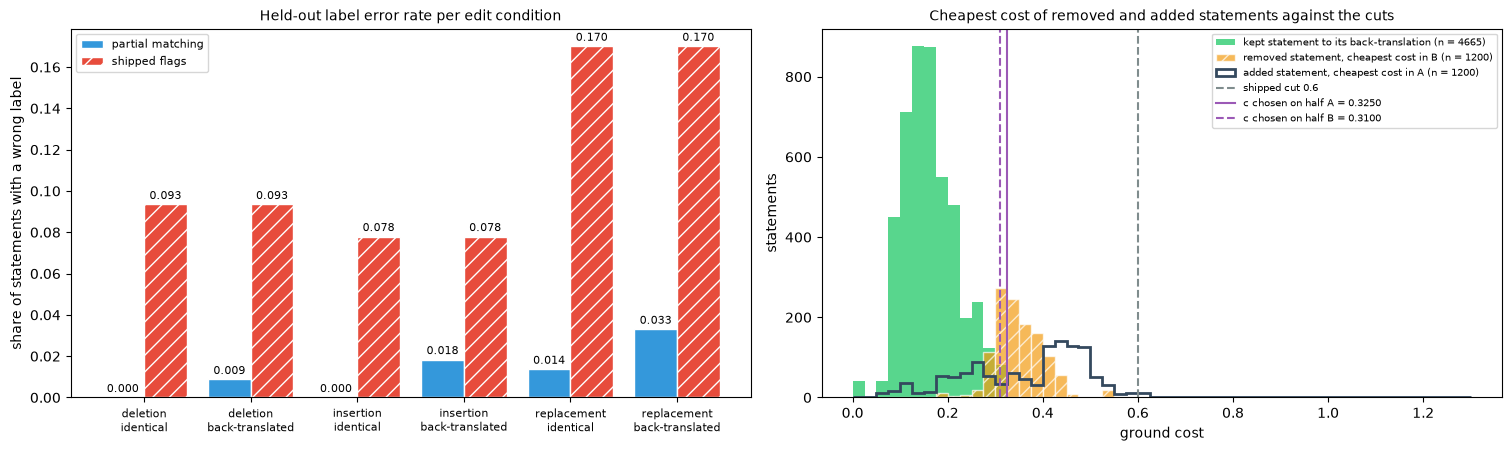

In [17]:
if GATE_PASSED:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), constrained_layout=True)

    ax = axes[0]
    labels = [f"{row['kind']}\n{'back-translated' if row['paraphrase'] else 'identical'}" for row in CONDITIONS]
    x = np.arange(len(CONDITIONS))
    for shift, labeller, name, hatch in ((-0.2, "pm", "proposed", ""), (0.2, "sh", "shipped", "//")):
        values = [row[labeller]["error_rate"] for row in CONDITIONS]
        bars = ax.bar(x + shift, values, 0.4, color=COLOR[name], hatch=hatch, edgecolor="white",
                      label="partial matching" if name == "proposed" else "shipped flags")
        ax.bar_label(bars, labels=[f"{v:.3f}" for v in values], fontsize=8, padding=2)
    ax.set_xticks(x, labels, fontsize=8)
    ax.set_ylabel("share of statements with a wrong label")
    ax.set_title("Held-out label error rate per edit condition", fontsize=10)
    ax.legend(fontsize=8)

    ax = axes[1]
    bins = np.linspace(0, 1.3, 53)
    ax.hist(kept_cost, bins=bins, color=COLOR["pair"], alpha=0.8, label=f"kept statement to its back-translation (n = {kept_cost.size})")
    ax.hist(removed_cost, bins=bins, color=COLOR["neighbour"], alpha=0.7, hatch="//", edgecolor="white",
            label=f"removed statement, cheapest cost in B (n = {removed_cost.size})")
    ax.hist(added_cost, bins=bins, histtype="step", lw=2, color=COLOR["added"],
            label=f"added statement, cheapest cost in A (n = {added_cost.size})")
    ax.axvline(SHIPPED_CUT, color=COLOR["reference"], ls="--", lw=1.5, label=f"shipped cut {SHIPPED_CUT}")
    for (calibration, scored), style in zip(DIRECTIONS, ("-", "--")):
        ax.axvline(HELD_OUT[(calibration, scored)]["cutoff"], color=COLOR["cutoff"], ls=style, lw=1.5,
                   label=f"c chosen on half {calibration} = {HELD_OUT[(calibration, scored)]['cutoff']:.4f}")
    ax.set_xlabel("ground cost")
    ax.set_ylabel("statements")
    ax.set_title("Cheapest cost of removed and added statements against the cuts", fontsize=10)
    ax.legend(fontsize=7)
    plt.show()

## Guardrails

Measured, not asserted. `V` counts the ordinality violations over the 6 gold x 4 adversarial comparisons of the
ibm panel on the shipped default path. The lever is an annotation computed from the shipped cost matrix, so
the two distances must be unchanged: the panel's `smd` and `order_gap` are re-read after the experiment and
compared with `np.array_equal` against the reading taken before it. The source tree is fingerprinted at the
start and at the end, and `git status` is read for `src/` and `tests/`.

In [18]:
PANEL_AFTER = panel_reading()
tiers = np.array([tier for _, _, tier in PANEL[1:]])
gold_smd, adversarial_smd = PANEL_AFTER[0][tiers == "gold"], PANEL_AFTER[0][tiers == "adversarial"]
V = int(sum(1 for g in gold_smd for a in adversarial_smd if g >= a))
V_TOTAL = int(gold_smd.size * adversarial_smd.size)
SMD_IDENTICAL = bool(np.array_equal(PANEL_BEFORE[0], PANEL_AFTER[0]))
GAP_IDENTICAL = bool(np.array_equal(PANEL_BEFORE[1], PANEL_AFTER[1]))
FINGERPRINT_END = tree_fingerprint()
GIT_STATUS = subprocess.run(["git", "status", "--porcelain", "--", "src", "tests"], cwd=ROOT,
                            capture_output=True, text=True).stdout.strip()
SRC_UNTOUCHED = FINGERPRINT_START == FINGERPRINT_END and GIT_STATUS == ""
OVERRIDE_REMOVED = "embed_statements" not in vars(DD) and type(DD._segmenter).__name__ == "Segmenter"
GUARDRAILS_HOLD = V == 0 and SMD_IDENTICAL and GAP_IDENTICAL and SRC_UNTOUCHED and OVERRIDE_REMOVED

hold = lambda flag: "[green]holds[/green]" if flag else "[red]BREACH[/red]"
t = Table(title="Guardrails", title_style="bold cyan")
t.add_column("guardrail")
t.add_column("reading", justify="right")
t.add_column("verdict")
t.add_row("V on the ibm panel, shipped default path", f"{V}/{V_TOTAL}", hold(V == 0))
t.add_row("gold maximum against adversarial minimum (smd)", f"{gold_smd.max():.4f} < {adversarial_smd.min():.4f}",
          hold(gold_smd.max() < adversarial_smd.min()))
t.add_row(f"smd before = after, np.array_equal over {PANEL_AFTER[0].size} anchor pairs", str(SMD_IDENTICAL), hold(SMD_IDENTICAL))
t.add_row(f"order_gap before = after, np.array_equal over {PANEL_AFTER[1].size} anchor pairs", str(GAP_IDENTICAL), hold(GAP_IDENTICAL))
t.add_row("src/ and tests/ fingerprint start = end", f"{FINGERPRINT_START[:16]} = {FINGERPRINT_END[:16]}",
          hold(FINGERPRINT_START == FINGERPRINT_END))
t.add_row("git status --porcelain -- src tests", "empty" if GIT_STATUS == "" else GIT_STATUS.replace("\n", "; "),
          hold(GIT_STATUS == ""))
t.add_row("instance overrides removed (embed_statements wrapper, pinned segmenter)", str(OVERRIDE_REMOVED),
          hold(OVERRIDE_REMOVED))
console.print(t)
print(f"GUARDRAILS: {'ALL HOLD' if GUARDRAILS_HOLD else 'BREACHED'}")

                                                        Guardrails                                                         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ guardrail                                                               ┃                             reading ┃ verdict ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ V on the ibm panel, shipped default path                                │                                0/24 │ holds   │
│ gold maximum against adversarial minimum (smd)                          │                     0.2907 < 0.3573 │ holds   │
│ smd before = after, np.array_equal over 10 anchor pairs                 │                                True │ holds   │
│ order_gap before = after, np.array_equal over 10 anchor pairs           │                                True │ holds   │
│ src/ and tests/ fingerprint start = end                                 │ 905a308ecd1b29d1 = 905a308ecd1b29d1 │ holds   │
│ git status --porcelain -- src tests                                     │                               empty │ holds   │
│ instance overrides removed (embed_statements wrapper, pinned segmenter) │                                True │ holds   │
└─────────────────────────────────────────────────────────────────────────┴─────────────────────────────────────┴─────────┘

GUARDRAILS: ALL HOLD


## Acceptance bar and verdict

The bar is read literally and on both directions: held-out macro-F1 ≥ 0.90 and a gain of at least +0.30 over
the shipped-flag baseline on the same labels, with c chosen on the calibration half only. The prediction is
checked separately: removed and added F1 ≥ 0.90 for the partial matching, ≤ 0.30 for the shipped flags, and
both calibrated cutoffs strictly between 0.348 and 0.6.

In [19]:
BAR_TEXT = (f"held-out macro-F1 over {{kept, removed, added}} >= {BAR_MACRO_F1} AND >= +{BAR_DELTA} above the "
            f"shipped-flag baseline on the same labels, c chosen on the calibration split only, both directions")
BAR_MET, PREDICTION_DIRECTION, PREDICTION_HELD, BAR_READINGS, PREDICTION = False, False, False, {}, {}
if GATE_PASSED:
    for (calibration, scored), r in HELD_OUT.items():
        BAR_READINGS[f"{calibration} → {scored}"] = {
            "cutoff": r["cutoff"],
            "macro_f1_partial_matching": round(r["proposed"]["macro_f1"], 4),
            "macro_f1_shipped_flags": round(r["shipped"]["macro_f1"], 4),
            "gain": round(r["delta"], 4),
            "met": bool(r["proposed"]["macro_f1"] >= BAR_MACRO_F1 and r["delta"] >= BAR_DELTA),
        }
    BAR_MET = all(r["met"] for r in BAR_READINGS.values())
    results = list(HELD_OUT.values())
    PREDICTION = {
        "partial_matching_removed_f1_min": round(min(r["proposed"]["f1"][REMOVED] for r in results), 4),
        "partial_matching_added_f1_min": round(min(r["proposed"]["f1"][ADDED] for r in results), 4),
        "shipped_removed_f1_max": round(max(r["shipped"]["f1"][REMOVED] for r in results), 4),
        "shipped_added_f1_max": round(max(r["shipped"]["f1"][ADDED] for r in results), 4),
        "cutoffs": [r["cutoff"] for r in results],
    }
    PREDICTION["class_f1_held"] = bool(min(PREDICTION["partial_matching_removed_f1_min"],
                                           PREDICTION["partial_matching_added_f1_min"]) >= PRED_CLASS_F1)
    PREDICTION["shipped_f1_held"] = bool(max(PREDICTION["shipped_removed_f1_max"],
                                             PREDICTION["shipped_added_f1_max"]) <= PRED_SHIPPED_F1)
    PREDICTION["cutoff_band_held"] = bool(all(E12_H60_MATCHED_MAX < c < SHIPPED_CUT for c in PREDICTION["cutoffs"]))
    PREDICTION_DIRECTION = PREDICTION["class_f1_held"] and PREDICTION["shipped_f1_held"]  # the two F1 parts
    PREDICTION_HELD = PREDICTION_DIRECTION and PREDICTION["cutoff_band_held"]  # every part, cutoff location included

if not SANITY_PASSED:
    VERDICT = "Blocked"
elif not GATE_PASSED:
    VERDICT = "Killed-at-gate"
elif not GUARDRAILS_HOLD:
    VERDICT = "Blocked"
elif BAR_MET:
    VERDICT = "Promoted"
elif all(abs(r["gain"]) < NULL_DELTA for r in BAR_READINGS.values()):
    VERDICT = "Refuted (null)"
else:
    VERDICT = "Refuted"

if not SANITY_PASSED:
    VERDICT_NUMBER = SANITY_READING
elif not GATE_PASSED:
    VERDICT_NUMBER = GATE_READING
else:
    VERDICT_NUMBER = "; ".join(
        f"{name}: held-out macro-F1 {r['macro_f1_partial_matching']:.4f} against {r['macro_f1_shipped_flags']:.4f} "
        f"for the shipped flags (gain {r['gain']:+.4f}) at c = {r['cutoff']:.4f}" for name, r in BAR_READINGS.items())

if GATE_PASSED:
    t = Table(title="Acceptance bar and prediction", title_style="bold cyan")
    t.add_column("condition")
    t.add_column("reading", justify="right")
    t.add_column("verdict")
    met = lambda flag: "[green]met[/green]" if flag else "[red]NOT MET[/red]"
    held = lambda flag: "[green]held[/green]" if flag else "[red]falsified[/red]"
    for name, r in BAR_READINGS.items():
        t.add_row(f"bar, {name}: macro-F1 >= {BAR_MACRO_F1}", f"{r['macro_f1_partial_matching']:.4f}",
                  met(r["macro_f1_partial_matching"] >= BAR_MACRO_F1))
        t.add_row(f"bar, {name}: gain >= +{BAR_DELTA}",
                  f"{r['gain']:+.4f} ({r['macro_f1_partial_matching']:.4f} - {r['macro_f1_shipped_flags']:.4f})",
                  met(r["gain"] >= BAR_DELTA))
    t.add_row(f"prediction: partial matching removed / added F1 >= {PRED_CLASS_F1} (minimum over directions)",
              f"{PREDICTION['partial_matching_removed_f1_min']:.4f} / {PREDICTION['partial_matching_added_f1_min']:.4f}",
              held(PREDICTION["class_f1_held"]))
    t.add_row(f"prediction: shipped removed / added F1 <= {PRED_SHIPPED_F1} (maximum over directions)",
              f"{PREDICTION['shipped_removed_f1_max']:.4f} / {PREDICTION['shipped_added_f1_max']:.4f}",
              held(PREDICTION["shipped_f1_held"]))
    t.add_row(f"prediction: cutoff in ({E12_H60_MATCHED_MAX}, {SHIPPED_CUT})",
              " and ".join(f"{c:.4f}" for c in PREDICTION["cutoffs"]), held(PREDICTION["cutoff_band_held"]))
    console.print(t)
console.print(Panel(f"[bold]{VERDICT}[/bold]\n{VERDICT_NUMBER}\n"
                    f"sanity passed: {SANITY_PASSED} | gate passed: {GATE_PASSED} | bar met: {BAR_MET} | "
                    f"prediction F1 parts held: {PREDICTION_DIRECTION} | prediction held in every part: "
                    f"{PREDICTION_HELD} | guardrails hold: {GUARDRAILS_HOLD}",
                    title="[bold]E13-H71 verdict[/bold]", border_style="green" if VERDICT == "Promoted" else "red",
                    width=150))

                                               Acceptance bar and prediction                                                
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ condition                                                                        ┃                   reading ┃ verdict   ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ bar, A → B: macro-F1 >= 0.9                                                      │                    0.9772 │ met       │
│ bar, A → B: gain >= +0.3                                                         │ +0.6642 (0.9772 - 0.3130) │ met       │
│ bar, B → A: macro-F1 >= 0.9                                                      │                    0.9457 │ met       │
│ bar, B → A: gain >= +0.3                                                         │ +0.6191 (0.9457 - 0.3266) │ met       │
│ prediction: partial matching removed / added F1 >= 0.9 (minimum over directions) │           0.9441 / 0.9030 │ held      │
│ prediction: shipped removed / added F1 <= 0.3 (maximum over directions)          │           0.0000 / 0.0392 │ held      │
│ prediction: cutoff in (0.348, 0.6)                                               │         0.3250 and 0.3100 │ falsified │
└──────────────────────────────────────────────────────────────────────────────────┴───────────────────────────┴───────────┘

╭───────────────────────────────────────────────────────────────── E13-H71 verdict ──────────────────────────────────────────────────────────────────╮
│ Promoted                                                                                                                                           │
│ A → B: held-out macro-F1 0.9772 against 0.3130 for the shipped flags (gain +0.6642) at c = 0.3250; B → A: held-out macro-F1 0.9457 against 0.3266  │
│ for the shipped flags (gain +0.6191) at c = 0.3100                                                                                                 │
│ sanity passed: True | gate passed: True | bar met: True | prediction F1 parts held: True | prediction held in every part: False | guardrails hold: │
│ True                                                                                                                                               │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Save - metrics JSON

Writes every measured number to `reports/E13-H71-partial-matching-map-metrics.json`: the two cost populations
of the kill-gate with their percentiles (the build stage reads the cutoff from there), the calibrated cutoffs,
the held-out scores, the per-condition and mechanism readings, the guardrails and the stage A result block.

In [20]:
def to_builtin(value):
    # numpy scalars to their Python value; any other type is a programming error
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"not JSON serialisable: {type(value).__name__}")


def score_block(s: dict) -> dict:
    return {"macro_f1": round(s["macro_f1"], 4),
            **{m: {name: round(float(s[m][k]), 4) for k, name in enumerate(CLASS_NAMES)}
               for m in ("f1", "precision", "recall")}}


def held_out_block(r: dict) -> dict:
    return {"cutoff": r["cutoff"], "calibration_macro_f1": round(r["calibration_macro_f1"], 4),
            "calibration_cutoff_range_at_or_above_bar": r["calibration_bar_range"],
            "n_pairs": r["n_pairs"], "n_statements": r["n_statements"], "gain": round(r["delta"], 4),
            "partial_matching": score_block(r["proposed"]), "shipped_flags": score_block(r["shipped"])}


def population_block(key: str) -> dict:
    values = np.concatenate([GATE[h][key] for h in ("A", "B")])
    return {"values": {h: [round(float(v), 6) for v in GATE[h][key]] for h in ("A", "B")},
            "percentiles": {"half_A": percentiles(GATE["A"][key]), "half_B": percentiles(GATE["B"][key]),
                            "all": percentiles(values)}}


CUTOFF = {
    "rule": "midpoint of the longest run of grid points at the maximum calibration macro-F1",
    "grid": {"low": float(C_GRID[0]), "high": float(C_GRID[-1]), "step": 0.005},
    "shipped_no_counterpart_cost": SHIPPED_CUT,
    "population_interval": {h: {"low": round(GATE[h]["cutoff_low"], 4), "high": round(GATE[h]["cutoff_high"], 4),
                                "mid": round(GATE[h]["cutoff_mid"], 4), "balanced_accuracy": round(GATE[h]["max"], 4)}
                            for h in ("A", "B", "all")},
}
if GATE_PASSED:
    CUTOFF["calibrated_on_half_A"] = HELD_OUT[("A", "B")]["cutoff"]
    CUTOFF["calibrated_on_half_B"] = HELD_OUT[("B", "A")]["cutoff"]
    CUTOFF["calibrated_on_all_bases_in_sample"] = SECONDARY["in-sample, all bases → all bases"]["cutoff"]
    ranges = {h: HELD_OUT[(h, other)]["calibration_bar_range"] for h, other in DIRECTIONS}
    CUTOFF["range_with_macro_f1_at_or_above_bar"] = {
        "half_A": ranges["A"], "half_B": ranges["B"],
        "both_halves": [max(ranges["A"][0], ranges["B"][0]), min(ranges["A"][1], ranges["B"][1])]}
    CUTOFF["macro_f1_at_fixed_cutoffs"] = FIXED

if not GATE_PASSED:
    SUMMARY = f"Kill-gate fired. {GATE_READING}. No edit fixture was built and the bar was not evaluated."
else:
    ab, ba = BAR_READINGS["A → B"], BAR_READINGS["B → A"]
    k = MECHANISM["kept_counterpart"]
    weakest = min(PER_BASE, key=lambda b: PER_BASE[b]["proposed"])
    both = CUTOFF["range_with_macro_f1_at_or_above_bar"]["both_halves"]
    SUMMARY = (
        f"{VERDICT}. Held-out macro-F1 of the unit-capacity partial matching is {ab['macro_f1_partial_matching']:.4f} "
        f"(c = {ab['cutoff']:.4f} chosen on half A, scored on half B) and {ba['macro_f1_partial_matching']:.4f} "
        f"(c = {ba['cutoff']:.4f} chosen on half B, scored on half A), against {ab['macro_f1_shipped_flags']:.4f} and "
        f"{ba['macro_f1_shipped_flags']:.4f} for the shipped flags on the same labels (gain {ab['gain']:+.4f} and "
        f"{ba['gain']:+.4f}). Bar met: {BAR_MET}. Minimum removed / added F1 over the two directions: "
        f"{PREDICTION['partial_matching_removed_f1_min']:.4f} / {PREDICTION['partial_matching_added_f1_min']:.4f} "
        f"for the partial matching, maximum {PREDICTION['shipped_removed_f1_max']:.4f} / "
        f"{PREDICTION['shipped_added_f1_max']:.4f} for the shipped flags. Kept statements pointed at their true "
        f"counterpart: {rate(k['partial_matching_correct'], k['n_kept'])} against "
        f"{rate(k['shipped_heaviest_correct'], k['n_kept'])} for the shipped heaviest target. Calibrated cutoffs "
        f"{ab['cutoff']:.4f} and {ba['cutoff']:.4f} against the predicted band ({E12_H60_MATCHED_MAX}, {SHIPPED_CUT}): "
        f"{'inside' if PREDICTION['cutoff_band_held'] else 'outside'}. No-edit control (unedited base against its "
        f"back-translation): {rate(MECHANISM['no_edit_control']['read_as_removed'], MECHANISM['no_edit_control']['n_statements'])} "
        f"statements read as removed. Per scored base document the macro-F1 runs from "
        f"{PER_BASE[weakest]['proposed']:.4f} ({weakest}) to {max(r['proposed'] for r in PER_BASE.values()):.4f}. "
        f"Every cutoff in [{both[0]:.3f}, {both[1]:.3f}] keeps both halves at or above {BAR_MACRO_F1}. "
        f"Fixture: {len(PAIRS)} edited pairs over {len(BASES)} base documents."
    )

CAVEATS = (
    "Synthetic edits on 10 base documents, 7 of which summarise the same ibm article, so each half holds parallel "
    "summaries of the other half's content: the split is held out by document, not by article (the article-split "
    "rows are a secondary reading); each direction scores 5 documents, so the pooled reading depends on the "
    "document mix. Paraphrases are opus-mt back-translations, a mild rewording, and the calibrated "
    "cutoff sits at the top of that pair-cost population: a stronger rewording, another encoder or the anisotropy "
    f"pre-pass moves it (the E12-H60 matched maximum {E12_H60_MATCHED_MAX} already lies above both calibrated "
    "cutoffs). One encoder (mmBERT OpenVINO INT8, raw embeddings). A replacement whose donor is a sibling "
    "summary can restate the removed statement, so the construction label (removed plus added) is debatable there. "
    f"The H1 title line is dropped from the 7 ibm documents; donors come from the same half; {N_PINNED} of "
    f"{len(EDITS)} pairs needed the statement units pinned because SaT split a statement differently inside the "
    "edited text (a reduced trial of 180 pairs showed this before the registered run, and pinning was chosen over "
    "excluding those pairs; the split, the donor rule, the calibration rule, the grid and the class definitions "
    "did not change after the trial; the rows on the unmodified segmentation alone are a secondary reading). The record "
    "does not fix the number of draws, the donor rule or the calibration rule; they were fixed in the "
    "configuration cell before the registered run."
)

RESULT = {
    "id": "E13-H71", "slug": "partial-matching-map", "model": "opus",
    "verdict": VERDICT, "verdict_number": VERDICT_NUMBER,
    "kill_gate": {"ran": True, "passed": bool(GATE_PASSED), "reading": GATE_READING},
    "sanity_check": {"required": True, "passed": bool(SANITY_PASSED), "reading": SANITY_READING},
    "prediction_check": {
        "predicted": (f"removed / added F1 >= {PRED_CLASS_F1} against <= {PRED_SHIPPED_F1} for the shipped flags; "
                      f"the cutoff lands between {E12_H60_MATCHED_MAX} and {SHIPPED_CUT}"),
        "observed": ("not evaluated - the kill-gate fired" if not GATE_PASSED else
                     f"partial matching removed / added F1 minimum over the two directions "
                     f"{PREDICTION['partial_matching_removed_f1_min']:.4f} / {PREDICTION['partial_matching_added_f1_min']:.4f} "
                     f"({'held' if PREDICTION['class_f1_held'] else 'falsified'}); shipped flags removed / added F1 maximum "
                     f"{PREDICTION['shipped_removed_f1_max']:.4f} / {PREDICTION['shipped_added_f1_max']:.4f} "
                     f"({'held' if PREDICTION['shipped_f1_held'] else 'falsified'}); calibrated cutoffs "
                     + " and ".join(f"{c:.4f}" for c in PREDICTION["cutoffs"])
                     + f" against the predicted band ({E12_H60_MATCHED_MAX}, {SHIPPED_CUT}) "
                     f"({'held' if PREDICTION['cutoff_band_held'] else 'falsified'})"),
        "direction_matched": bool(PREDICTION_DIRECTION),
    },
    "acceptance": {"bar": BAR_TEXT, "met": bool(BAR_MET), "readings": BAR_READINGS},
    "guardrails": {
        "V": f"{V}/{V_TOTAL}", "src_untouched": bool(SRC_UNTOUCHED),
        "metric_property": (f"untouched - the map is an annotation read from the shipped cost matrix, not a distance; "
                            f"smd np.array_equal before/after: {SMD_IDENTICAL}, order_gap np.array_equal before/after: "
                            f"{GAP_IDENTICAL} ({PANEL_AFTER[0].size} anchor pairs each)"),
        "notes": (f"source-tree fingerprint start = end: {FINGERPRINT_START == FINGERPRINT_END}; git status for src and "
                  f"tests: {'empty' if GIT_STATUS == '' else GIT_STATUS}; instance overrides (embed_statements wrapper, "
                  f"pinned segmenter) removed after the loop: {OVERRIDE_REMOVED}"),
    },
    "key_numbers": {},
    "result_summary": SUMMARY,
    "artifacts": {"notebook": "notebooks/experiments/E13-H71-kj-partial-matching-map.ipynb",
                  "metrics_json": "reports/E13-H71-partial-matching-map-metrics.json",
                  "log": "logs/E13-H71-partial-matching-map.log"},
    "notebook_errors": 0,
    "caveats": CAVEATS,
}
if GATE_PASSED:
    k, c = MECHANISM["kept_counterpart"], MECHANISM["cheapest_cost"]
    RESULT["key_numbers"] = {
        "n_pairs_scored": len(PAIRS), "n_pairs_built": len(EDITS), "n_pairs_segmentation_pinned": N_PINNED,
        "cutoff_half_A": CUTOFF["calibrated_on_half_A"], "cutoff_half_B": CUTOFF["calibrated_on_half_B"],
        "cutoff_all_bases_in_sample": CUTOFF["calibrated_on_all_bases_in_sample"],
        "gate_balanced_accuracy_half_A": round(GATE["A"]["max"], 4),
        "gate_balanced_accuracy_half_B": round(GATE["B"]["max"], 4),
        "true_pair_cost_max": round(float(GATE["all"]["pair"].max()), 4),
        "nearest_non_counterpart_cost_min": round(float(GATE["all"]["neighbour"].min()), 4),
        "held_out": {f"{a} → {b}": held_out_block(r) for (a, b), r in HELD_OUT.items()},
        "cutoff_range_both_halves_at_or_above_bar": CUTOFF["range_with_macro_f1_at_or_above_bar"]["both_halves"],
        "macro_f1_at_fixed_cutoffs": FIXED,
        "per_base_macro_f1_partial_matching_min": round(min(r["proposed"] for r in PER_BASE.values()), 4),
        "per_base_macro_f1_partial_matching_max": round(max(r["proposed"] for r in PER_BASE.values()), 4),
        "kept_counterpart_partial_matching": rate(k["partial_matching_correct"], k["n_kept"]),
        "kept_counterpart_shipped_heaviest_target": rate(k["shipped_heaviest_correct"], k["n_kept"]),
        "removed_statements_above_shipped_cut": rate(c["removed_statement_to_B"]["above_shipped_cut"], c["removed_statement_to_B"]["n"]),
        "added_statements_above_shipped_cut": rate(c["added_statement_to_A"]["above_shipped_cut"], c["added_statement_to_A"]["n"]),
        "shipped_targets_per_statement": MECHANISM["targets_per_statement"],
        "no_edit_control_read_as_removed": rate(MECHANISM["no_edit_control"]["read_as_removed"],
                                                MECHANISM["no_edit_control"]["n_statements"]),
        "replacement_pair_below_applied_cutoff": {group: rate(r["below_applied_cutoff"], r["n"])
                                                  for group, r in MECHANISM["replacement_pair_cost"].items()},
        "secondary_macro_f1": {name: {"cutoff": r["cutoff"], "partial_matching": round(r["proposed"]["macro_f1"], 4),
                                      "shipped_flags": round(r["shipped"]["macro_f1"], 4)}
                               for name, r in SECONDARY.items()},
    }

METRICS = {
    "id": "E13-H71", "slug": "partial-matching-map",
    "generated": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "docdistance_version": pipe._VERSION,
    "config": {
        "seed": SEED, "reps": REPS, "edit_kinds": EDIT_KINDS, "edit_ks": EDIT_KS, "paraphrase_arms": PARAPHRASE_ARMS,
        "half_A": HALF_BASES["A"], "half_B": HALF_BASES["B"], "excluded_bases": EXCLUDED,
        "donor_rule": "statements of the other base documents of the same half, exact duplicates of a base statement left out",
        "title_rule": "a leading H1 title line is dropped from the base and from its back-translation",
        "bar_reading": "both directions must meet both conditions",
        "backend": "OpenVINO INT8, CPU", "shipped_cut": SHIPPED_CUT,
    },
    "sanity_check": {"passed": bool(SANITY_PASSED), "reading": SANITY_READING, "per_base": ALIGNMENT},
    "kill_gate": {
        "rule": f"best balanced accuracy of `cost < c is a counterpart` >= {GATE_BA_MIN} on each calibration split",
        "passed": bool(GATE_PASSED), "reading": GATE_READING,
        "per_split": {h: {"bases": GATE[h]["bases"], "n": GATE[h]["n"], "best_balanced_accuracy": round(GATE[h]["max"], 4),
                          "cutoff_low": round(GATE[h]["cutoff_low"], 4), "cutoff_high": round(GATE[h]["cutoff_high"], 4),
                          "pairs_at_or_above_neighbour_min": GATE[h]["pairs_at_or_above_neighbour_min"],
                          "neighbours_at_or_below_pair_max": GATE[h]["neighbours_at_or_below_pair_max"]}
                      for h in ("A", "B", "all")},
    },
    "cost_populations": {
        "definition": {
            "true_paraphrase_pairs": "ground cost between base statement i and its own back-translation",
            "nearest_non_counterpart": "per base statement i, the smallest ground cost to a back-translated statement j != i of the same document",
            "scale": "shipped ground cost sqrt(2 - 2cos) on [0, sqrt(2)], OpenVINO INT8 embeddings, title lines dropped",
        },
        "true_paraphrase_pairs": population_block("pair"),
        "nearest_non_counterpart": population_block("neighbour"),
    },
    "cutoff": CUTOFF,
    "fixture": {"n_pairs_built": len(EDITS), "n_pairs_scored": len(PAIRS), "n_segmentation_pinned": N_PINNED,
                "n_computed_this_execution": N_COMPUTED, "n_restored_from_checkpoint": N_RESTORED},
    "held_out": {f"{a} → {b}": held_out_block(r) for (a, b), r in HELD_OUT.items()},
    "secondary": {name: held_out_block(r) for name, r in SECONDARY.items()},
    "macro_f1_curve": ({} if not GATE_PASSED else
                       {"cutoff": [float(c) for c in C_GRID],
                        **{f"half_{h}": [round(float(v), 4) for v in macro_f1_curve(pairs_of(HALF_BASES[h]))] for h in ("A", "B")}}),
    "conditions": CONDITIONS,
    "per_base": {b: {key: v if isinstance(v, int) else round(float(v), 4) for key, v in r.items()}
                 for b, r in PER_BASE.items()},
    "mechanism": MECHANISM,
    "prediction": PREDICTION,
    "acceptance": {"bar": BAR_TEXT, "met": bool(BAR_MET), "readings": BAR_READINGS},
    "guardrails": {
        "V": f"{V}/{V_TOTAL}", "gold_smd_max": round(float(gold_smd.max()), 6),
        "adversarial_smd_min": round(float(adversarial_smd.min()), 6),
        "smd_array_equal_before_after": SMD_IDENTICAL, "order_gap_array_equal_before_after": GAP_IDENTICAL,
        "fingerprint_start": FINGERPRINT_START, "fingerprint_end": FINGERPRINT_END, "git_status_src_tests": GIT_STATUS,
        "src_untouched": bool(SRC_UNTOUCHED), "instance_override_removed": bool(OVERRIDE_REMOVED),
        "all_hold": bool(GUARDRAILS_HOLD),
    },
    "result": RESULT,
}
REPORT.parent.mkdir(parents=True, exist_ok=True)
REPORT.write_text(json.dumps(METRICS, indent=2, ensure_ascii=False, default=to_builtin) + "\n")
print(f"wrote {REPORT} ({REPORT.stat().st_size} bytes)\n")
print(json.dumps(RESULT, indent=2, ensure_ascii=False, default=to_builtin))

wrote /home/lab/workspace/learning/projects/docdistance/reports/E13-H71-partial-matching-map-metrics.json (55222 bytes)

{
  "id": "E13-H71",
  "slug": "partial-matching-map",
  "model": "opus",
  "verdict": "Promoted",
  "verdict_number": "A → B: held-out macro-F1 0.9772 against 0.3130 for the shipped flags (gain +0.6642) at c = 0.3250; B → A: held-out macro-F1 0.9457 against 0.3266 for the shipped flags (gain +0.6191) at c = 0.3100",
  "kill_gate": {
    "ran": true,
    "passed": true,
    "reading": "calibration half A: best balanced accuracy 0.9915 for any cutoff in (0.2978, 0.2990], n = 59 statements; calibration half B: best balanced accuracy 0.9914 for any cutoff in (0.2621, 0.2672], n = 58 statements; gate threshold 0.9"
  },
  "sanity_check": {
    "required": true,
    "passed": true,
    "reading": "10 of 10 base documents align one-to-one with their back-translation (equal length, identity optimal under the shipped ground cost and under a lexical cost, exact re-segmentatio

## Conclusions

**Verdict - `Promoted`.** The unit-capacity partial matching meets the registered bar in both directions of the 5 / 5 split, with the cutoff chosen on the calibration half only. The prediction holds in its two F1 parts and fails in its third part, the location of the cutoff.

**Bar readings (held-out)**

| Direction | c | Partial matching macro-F1 | Shipped flags macro-F1 | Gain | Bar |
|---|---|---|---|---|---|
| A → B | 0.3250 | 0.9772 | 0.3130 | +0.6642 | met |
| B → A | 0.3100 | 0.9457 | 0.3266 | +0.6191 | met |

- **Per class** - partial matching F1 kept / removed / added is 0.9959 / 0.9831 / 0.9525 on half B and 0.9901 / 0.9441 / 0.9030 on half A; the shipped flags score 0.0000 on removed in both directions and 0.0000 / 0.0392 on added
- **Kill-gate** - passed on both calibration halves: best balanced accuracy 0.9915 (half A, 59 statements) and 0.9914 (half B, 58 statements) against the 0.90 gate
- **Sanity check** - 10 of 10 base documents align one-to-one with their back-translation; the first list element is an H1 title line on 7 of 10 files and was dropped there
- **Fixture** - 900 edited pairs, 1200 removed and 1200 added statements; 37 pairs needed the statement units pinned, and the reading on the 863 pairs with unmodified segmentation is 0.9773 / 0.9467, the same verdict

**Mechanism - what the outputs support**

- **Forced split confirmed** - the shipped plan spreads an A statement over 1.7179 targets after a deletion and 2.0598 after an insertion, and over 1.0000 when the lengths are equal (replacement)
- **Shipped flags are silent because of the cost scale, not because of the plan** - 0 of 1200 removed statements have a cheapest cost in B above 0.6 (maximum 0.5455) and 12 of 1200 added statements have a cheapest cost in A above 0.6; the 0.6 cut cannot fire on this encoder's cost range
- **Unit capacity carries most of the gain** - with the cutoff set to the shipped 0.600, so that capacity is the only change, the macro-F1 read off the curves is 0.7828 (half A) and 0.7713 (half B). At the calibrated cutoffs, deletions and insertions with identical kept statements carry 0 label errors over 3210 and 3810 statements
- **The cutoff decides replacements, as the record states** - the calibrated cutoffs score 0.9457 (half A) and 0.9772 (half B) held-out; replacement pairs with identical kept statements still carry 48 label errors (24 removed statements read as kept and 24 added statements read as kept)
- **One mechanism claim is not supported** - "a kept statement keeps its counterpart" shows no gain: the shipped heaviest target already points at the true counterpart for 9286 of 9330 kept statements (0.9953), the partial matching for 9244 (0.9908). The whole gain is in the removed and added classes

**Cutoff - where it lands and why the prediction missed**

- **Predicted (0.348, 0.6), measured 0.3250 and 0.3100** - the cutoff has to stay above the paraphrase pair costs (p95 0.2687, maximum 0.3229) and below the cost of a removed statement against its replacement (sibling-summary donors: p5 0.2900, p50 0.4112; other donors: minimum 0.3304, p50 0.5114). These populations lie closer together than the record assumed
- **Tolerant range** - every cutoff in [0.280, 0.440] keeps both halves at or above 0.90 on their own curves; the curves read 0.9674 / 0.9772 at 0.325, 0.9538 / 0.9665 at 0.350 and 0.8691 / 0.8492 at 0.500 (curve readings, not held-out scores)
- **The balanced-accuracy optimum of the two gate populations is not the cutoff** - the midpoint read from half B (0.2647) scores 0.8461 on half A. Under unit capacity the nearest non-counterpart is normally taken by its own counterpart, so the cutoff does not have to exclude it; it has to clear the pair costs. The build stage should read the cutoff from the `cutoff` block of the metrics file (0.325 calibrated on half A and on all 10 bases, 0.31 on half B) and from the top of the true-pair population (p99 0.3055, p100 0.3229), not from the balanced-accuracy interval

**Where it fails**

- **No headroom above the largest pair cost** - the largest pair cost of `haiku` (0.3229) lies above the cutoff applied to it (0.3100): `haiku` carries 87 kept statements read as removed or added against 0 to 11 on the other nine bases, its macro-F1 is 0.8686 against 0.9378 to 1.0000 for the others, and the no-edit control reads 1 of 117 statements as removed (`haiku`). The E12-H60 matched maximum 0.348 lies above both calibrated cutoffs, so a rewording stronger than opus-mt back-translation will produce false removed / added pairs
- **Sibling-summary donors** - an added statement is found for 622 of 622 donors from another article and 72 of 72 from another section, and for 417 of 506 donors from a sibling summary (0.8241). A sibling summary can restate a base statement, so the construction label is debatable exactly where the errors concentrate; 45 of the 46 removed statements read as kept were matched to an added statement
- **Segmentation** - SaT split a statement differently inside 37 of 900 edited texts (33 in the back-translated arm). A statement-level map inherits the stability of the statement units

**Guardrails** - `V` = 0/24 on the shipped default path (gold maximum 0.2907 below adversarial minimum 0.3573); `smd` and `order_gap` equal under `np.array_equal` before and after over 10 anchor pairs each; the `src/` and `tests/` fingerprint is unchanged and `git status` is empty for both; both instance overrides were removed after the loop. The map is an annotation read from the shipped cost matrix. It is not a distance and not a metric, and neither distance changes.

**Limits of this evidence**

- **Held out by document, not by article** - 7 of the 10 bases summarise one ibm article, so each half contains parallel summaries of the other half. The article split is a secondary reading: 1.0000 (ibm → wergeland, c = 0.3250) and 0.9185 (wergeland → ibm, c = 0.2950)
- **One encoder, one paraphrase strength** - mmBERT OpenVINO INT8 on raw embeddings and opus-mt back-translation; the anisotropy pre-pass, another encoder or stronger rewording changes the cost scale and needs its own calibration
- **Five scored documents per direction** - the pooled reading depends on the document mix: the per-base macro-F1 runs from 0.8686 to 1.0000
- **Synthetic edits** - labels come from the construction; no human-labelled edit set was scored

**Impact** - the detail files can carry a per-statement matched / removed / added reading that the shipped `no_counterpart` and `min_incoming_cost` readings do not provide on this encoder (0 of 1200 removed and 12 of 1200 added statements flagged). The cutoff is an encoder-specific constant with a measured tolerant range of [0.280, 0.440] and should ship as a named threshold beside the existing ones, with the calibration caveats above.
